# CP0

In [1]:
import ee
ee.Authenticate()
ee.Initialize(project='earth-engine-uhi')  # Pune ID-ul exact copiat la Pasul 2

print("Conexiunea la Earth Engine funcționează perfect!")

Conexiunea la Earth Engine funcționează perfect!


## Verificari si observatii asupra datelor folosite

In [2]:
import ee

# 1. Definim punctul central (București) și un buffer de analiză
bucuresti_center = ee.Geometry.Point([26.1025, 44.4268])

# 2. Interogăm colecția Landsat 8/9 Level-2 (Termic - LST)
# Filtrăm: Iunie - August 2023, nori sub 20%
landsat_summer = (ee.ImageCollection('LANDSAT/LC08/C02/T1_L2')
                  .filterBounds(bucuresti_center)
                  .filterDate('2026-06-01', '2026-08-31')
                  .filter(ee.Filter.lt('CLOUD_COVER', 20)))

# 3. Interogăm colecția Sentinel-2 Level-2A (Optic - NDVI/NDBI)
# Același interval temporal
sentinel_summer = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
                   .filterBounds(bucuresti_center)
                   .filterDate('2023-06-01', '2023-08-31')
                   .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20)))

# Extragem metadatele ca dovadă de acces
l8_dates = landsat_summer.aggregate_array('DATE_ACQUIRED').getInfo()
l8_count = landsat_summer.size().getInfo()
s2_count = sentinel_summer.size().getInfo()

print("=" * 60)
print(f"DOVADĂ ACCESARE SURSA 1 (Landsat 8 - LST):")
print(f"  • Număr scene senine identificate: {l8_count}")
print(f"  • Datele de achiziție: {l8_dates}")
print("=" * 60)
print(f"DOVADĂ ACCESARE SURSA 1 (Sentinel-2 - Optic):")
print(f"  • Număr scene senine identificate: {s2_count}")
print("=" * 60)

DOVADĂ ACCESARE SURSA 1 (Landsat 8 - LST):
  • Număr scene senine identificate: 7
  • Datele de achiziție: ['2026-06-14', '2026-06-30', '2026-08-01', '2026-08-17', '2026-06-21', '2026-07-07', '2026-08-08']
DOVADĂ ACCESARE SURSA 1 (Sentinel-2 - Optic):
  • Număr scene senine identificate: 13


In [3]:
import ee
import pandas as pd

# 1. Punct central București
bucuresti_center = ee.Geometry.Point([26.1025, 44.4268])

# 2. Colecții filtrate (Vara 2023)
landsat_summer = (ee.ImageCollection('LANDSAT/LC08/C02/T1_L2')
                  .filterBounds(bucuresti_center)
                  .filterDate('2023-06-01', '2023-08-31')
                  .filter(ee.Filter.lt('CLOUD_COVER', 20)))

sentinel_summer = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
                   .filterBounds(bucuresti_center)
                   .filterDate('2023-06-01', '2023-08-31')
                   .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20)))

# 3. Funcții helper pentru extragerea proprietăților tabulare
def get_landsat_metadata(img):
    return ee.Feature(None, {
        'Satelit': 'Landsat 8 (TIRS/OLI)',
        'Tip_Date': 'Termic (LST) & Refl.',
        'Data_Achizitie': img.get('DATE_ACQUIRED'),
        'Acoperire_Nori_%': ee.Number(img.get('CLOUD_COVER')).round(),
        'Scene_ID': img.get('system:index')
    })

def get_sentinel_metadata(img):
    # Sentinel stochează data în timestamp milisecunde
    date_str = ee.Date(img.get('system:time_start')).format('YYYY-MM-dd')
    return ee.Feature(None, {
        'Satelit': 'Sentinel-2 (MSI)',
        'Tip_Date': 'Optic (NDVI / NDBI)',
        'Data_Achizitie': date_str,
        'Acoperire_Nori_%': ee.Number(img.get('CLOUDY_PIXEL_PERCENTAGE')).round(),
        'Scene_ID': img.get('system:index')
    })

# 4. Mapare și extragere în Python
l8_features = landsat_summer.map(get_landsat_metadata).getInfo()['features']
s2_features = sentinel_summer.map(get_sentinel_metadata).getInfo()['features']

# 5. Construire DataFrame
rows = [f['properties'] for f in l8_features] + [f['properties'] for f in s2_features]
df_scene = pd.DataFrame(rows)

# Sortare cronologică
df_scene['Data_Achizitie'] = pd.to_datetime(df_scene['Data_Achizitie'])
df_scene = df_scene.sort_values(by=['Data_Achizitie', 'Satelit']).reset_index(drop=True)

# Reordonare coloane
df_scene = df_scene[['Data_Achizitie', 'Satelit', 'Tip_Date', 'Acoperire_Nori_%', 'Scene_ID']]

# Afișare tabel formatat în notebook
display(df_scene)

,Data_Achizitie,Satelit,Tip_Date,Acoperire_Nori_%,Scene_ID
0,2023-06-06,Landsat 8 (TIRS/OLI),Termic (LST) & Refl.,7,LC08_182029_20230606
1,2023-06-22,Landsat 8 (TIRS/OLI),Termic (LST) & Refl.,9,LC08_182029_20230622
2,2023-06-24,Sentinel-2 (MSI),Optic (NDVI / NDBI),1,20230624T090601_20230624T091055_T35TMK
3,2023-06-29,Landsat 8 (TIRS/OLI),Termic (LST) & Refl.,13,LC08_183029_20230629
4,2023-06-29,Sentinel-2 (MSI),Optic (NDVI / NDBI),9,20230629T090559_20230629T091459_T35TMK
5,2023-07-04,Sentinel-2 (MSI),Optic (NDVI / NDBI),12,20230704T090601_20230704T091054_T35TMK
6,2023-07-09,Sentinel-2 (MSI),Optic (NDVI / NDBI),4,20230709T090559_20230709T091057_T35TMK
7,2023-07-14,Sentinel-2 (MSI),Optic (NDVI / NDBI),0,20230714T090601_20230714T091057_T35TMK
8,2023-07-15,Landsat 8 (TIRS/OLI),Termic (LST) & Refl.,15,LC08_183029_20230715
9,2023-07-19,Sentinel-2 (MSI),Optic (NDVI / NDBI),17,20230719T090559_20230719T091058_T35TMK


In [4]:
import ee

ee.Initialize(project='earth-engine-uhi')

# 1. Punct de control: Piața Universității, București
point_sample = ee.Geometry.Point([26.1025, 44.4355])

# 2. Sursa 3: WorldPop 100m (Populație)
worldpop = (ee.ImageCollection('WorldPop/GP/100m/pop')
            .filterBounds(point_sample)
            .filter(ee.Filter.eq('year', 2020))
            .first())

pop_val = worldpop.reduceRegion(
    reducer=ee.Reducer.first(),
    geometry=point_sample,
    scale=100
).getInfo()

# 3. Sursa 2b: GHSL Built-Up Grid (Copernicus JRC Built Surface Presence)
ghsl_built = ee.Image('JRC/GHSL/P2016/BUILT_LDSMT_GLOBE_V1')

built_val = ghsl_built.reduceRegion(
    reducer=ee.Reducer.first(),
    geometry=point_sample,
    scale=100
).getInfo()

print("=" * 60)
print("DOVADĂ ACCESARE SURSA 3 (WorldPop 100m - Populație):")
print(f"  • Asset ID: WorldPop/GP/100m/pop (anul 2020)")
print(f"  • Estimare populație per celulă 100m: {pop_val.get('population'):.1f} locuitori")
print("=" * 60)
print("DOVADĂ ACCESARE SURSA 2b (GHSL Urban Built-Up):")
print(f"  • Asset ID: JRC/GHSL/P2016/BUILT_LDSMT_GLOBE_V1")
print(f"  • Valoare grid construit (epoch classification): {built_val}")
print("=" * 60)

/usr/local/lib/python3.13/dist-packages/ee/deprecation.py:215: DeprecationWarning: 

Attention required for WorldPop/GP/100m/pop! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by WorldPop/GP/100m/R2025A/v1/pop

Learn more: https://developers.google.com/earth-engine/datasets/catalog/WorldPop_GP_100m_pop

  warnings.warn(warning, category=DeprecationWarning)
/usr/local/lib/python3.13/dist-packages/ee/deprecation.py:215: DeprecationWarning: 

Attention required for JRC/GHSL/P2016/BUILT_LDSMT_GLOBE_V1! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by JRC/GHSL/P2023A/GHS_BUILT_S

Learn more: https://developers.google.com/earth-engine/datasets/catalog/JRC_GHSL_P2016_BUILT_LDSMT_GLOBE_V1

  warnings.warn(warning, category=DeprecationWarning)


DOVADĂ ACCESARE SURSA 3 (WorldPop 100m - Populație):
  • Asset ID: WorldPop/GP/100m/pop (anul 2020)
  • Estimare populație per celulă 100m: 101.5 locuitori
DOVADĂ ACCESARE SURSA 2b (GHSL Urban Built-Up):
  • Asset ID: JRC/GHSL/P2016/BUILT_LDSMT_GLOBE_V1
  • Valoare grid construit (epoch classification): {'built': 6, 'cnfd': 236, 'dm': 16}


# CP1

# Data Card

In [5]:
import ee

ee.Initialize(project='earth-engine-uhi')

def inspect_gee_asset(asset_id: str, is_collection: bool = False):
    if is_collection:
        img = ee.ImageCollection(asset_id).first()
    else:
        img = ee.Image(asset_id)
        
    info = img.getInfo()
    bands = [b['id'] for b in info.get('bands', [])]
    
    # Selectăm prima bandă și îi extragem proiecția
    first_band = img.select(0)
    proj = first_band.projection()
    
    # Metoda corectă în EE Python API este nominalScale()
    nominal_scale = proj.nominalScale().getInfo()
    crs = proj.crs().getInfo()
    
    print(f"Dataset: {asset_id}")
    print(f"  • Număr total benzi: {len(bands)}")
    print(f"  • Primele benzi: {bands[:6]}")
    print(f"  • Rezoluție nominală: ~{round(nominal_scale, 2)} m")
    print(f"  • CRS nativ: {crs}")
    print("-" * 60)

# Verificare pentru sursele din proiect:
inspect_gee_asset('LANDSAT/LC08/C02/T1_L2', is_collection=True)
inspect_gee_asset('COPERNICUS/S2_SR_HARMONIZED', is_collection=True)
inspect_gee_asset('WorldPop/GP/100m/pop', is_collection=True)

Dataset: LANDSAT/LC08/C02/T1_L2
  • Număr total benzi: 19
  • Primele benzi: ['SR_B1', 'SR_B2', 'SR_B3', 'SR_B4', 'SR_B5', 'SR_B6']
  • Rezoluție nominală: ~30 m
  • CRS nativ: EPSG:32628
------------------------------------------------------------
Dataset: COPERNICUS/S2_SR_HARMONIZED
  • Număr total benzi: 26
  • Primele benzi: ['B1', 'B2', 'B3', 'B4', 'B5', 'B6']
  • Rezoluție nominală: ~60 m
  • CRS nativ: EPSG:32633
------------------------------------------------------------
Dataset: WorldPop/GP/100m/pop
  • Număr total benzi: 1
  • Primele benzi: ['population']
  • Rezoluție nominală: ~92.77 m
  • CRS nativ: EPSG:4326
------------------------------------------------------------


In [6]:
!pip install osmnx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.0/105.0 kB 2.3 MB/s eta 0:00:00ta 0:00:01


In [7]:
# import osmnx as ox
# import geopandas as gpd
# import pandas as pd

# # ==========================================
# # 1. Inspectare date OpenStreetMap (OSM)
# # ==========================================
# print("Interogare OpenStreetMap pentru eșantionul București...")
# coords = (44.4355, 26.1025) # Centru București

# # Descarcă amprente clădiri pe un eșantion de 500m
# gdf_buildings = ox.features_from_point(coords, tags={'building': True}, dist=500)

# # Păstrăm doar poligoanele valide
# gdf_buildings = gdf_buildings[gdf_buildings.geometry.type.isin(['Polygon', 'MultiPolygon'])]

# # Calculăm statistici descriptive specifice OSM
# # Proiectăm temporar în Stereo 70 (EPSG:3844) pentru calcule metrice reale
# gdf_proj = gdf_buildings.to_crs(epsg=3844)
# areas = gdf_proj.geometry.area

# print("=" * 60)
# print("METADATE OPENSTREETMAP (OSM) - Clădiri (Vectorial):")
# print(f"  • Tip geometrie: {gdf_buildings.geometry.type.unique()}")
# print(f"  • Număr obiecte în eșantion: {len(gdf_buildings)}")
# print(f"  • CRS descărcat nativ: {gdf_buildings.crs}")
# print(f"  • Aria medie a unei clădiri: {areas.mean():.1f} m² (Min: {areas.min():.1f} m², Max: {areas.max():.1f} m²)")
# print(f"  • Coloane/Atribute principale OSM disponibile:")
# for col in ['building', 'building:levels', 'height', 'addr:street']:
#     if col in gdf_buildings.columns:
#         valid_cnt = gdf_buildings[col].dropna().count()
#         print(f"     - {col}: {valid_cnt} valori nenule ({round(valid_cnt/len(gdf_buildings)*100, 1)}%)")
# print("=" * 60)

In [8]:
import ee

ee.Initialize(project='earth-engine-uhi')

# Copernicus GHSL Built-Up Grid
ghsl_asset_id = 'JRC/GHSL/P2016/BUILT_LDSMT_GLOBE_V1'
ghsl_img = ee.Image(ghsl_asset_id)

# Lista tuturor benzilor disponibile
bands = ghsl_img.bandNames().getInfo()

# Selectăm explicit prima bandă pentru a interoga proiecția și rezoluția
first_band = ghsl_img.select(0)
proj = first_band.projection()
scale = proj.nominalScale().getInfo()
crs = proj.crs().getInfo()

print("=" * 60)
print("METADATE COPERNICUS GHSL (Fond Construit):")
print(f"  • Asset ID: {ghsl_asset_id}")
print(f"  • Benzi: {bands}")
print(f"  • Rezoluție nominală: ~{round(scale, 1)} metri")
print(f"  • Sistem de coordonate: {crs}")
print("=" * 60)

METADATE COPERNICUS GHSL (Fond Construit):
  • Asset ID: JRC/GHSL/P2016/BUILT_LDSMT_GLOBE_V1
  • Benzi: ['built', 'cnfd', 'dm']
  • Rezoluție nominală: ~38.2 metri
  • Sistem de coordonate: EPSG:3857


# Colectarea datelor

In [9]:
import numpy as np
import geopandas as gpd
from shapely.geometry import Polygon, Point

# 1. Bounding box general București (WGS84)
bbox_wgs84 = (25.96, 44.33, 26.24, 44.55)

# 2. Conversie în Stereo 70 (EPSG:3844) pentru coordonate metrice reale
gdf_bbox = gpd.GeoDataFrame(
    geometry=[Polygon.from_bounds(*bbox_wgs84)], 
    crs="EPSG:4326"
).to_crs("EPSG:3844")

minx, miny, maxx, maxy = gdf_bbox.total_bounds
cell_size = 250  # 250 metri

x_coords = np.arange(minx, maxx, cell_size)
y_coords = np.arange(miny, maxy, cell_size)

polygons = []
cell_ids = []
idx = 0

for x in x_coords:
    for y in y_coords:
        poly = Polygon([
            (x, y),
            (x + cell_size, y),
            (x + cell_size, y + cell_size),
            (x, y + cell_size)
        ])
        polygons.append(poly)
        cell_ids.append(f"cell_{idx:05d}")
        idx += 1

gdf_grid = gpd.GeoDataFrame({
    'cell_id': cell_ids,
    'geometry': polygons
}, crs="EPSG:3844")

# 3. Delimitarea celor două zone de comparație (Exemplu: Centru vs Periferie sau Nord vs Sud)
# Definim centrul istoric / Piața Universității în Stereo 70
punct_centru_wgs84 = gpd.GeoDataFrame(
    geometry=[Point(26.1025, 44.4355)], crs="EPSG:4326"
).to_crs("EPSG:3844").geometry.iloc[0]

# Calculăm distanța fiecărui centroid de celulă până la centru
distante_centru = gdf_grid.geometry.centroid.distance(punct_centru_wgs84)

# ZONA A: Nucleu Urban Central (buffer < 4.5 km - densitate maximă, clădiri compacte)
# ZONA B: Coridor Periurban / Exterior (distanță > 4.5 km - mixt rezidențial, industrial, spații deschise)
gdf_grid['zone_label'] = np.where(distante_centru <= 4500, 'Nucleu_Urban_Central', 'Periferie_Periurban')

# Alternativă simplă: Împărțire Nord vs Sud folosind mediana axei Y
# y_mid = (miny + maxy) / 2
# gdf_grid['zone_label'] = np.where(gdf_grid.geometry.centroid.y >= y_mid, 'Bucuresti_Nord', 'Bucuresti_Sud')

# Versiunea în WGS84 necesară pentru interogarea Google Earth Engine
gdf_grid_wgs84 = gdf_grid.to_crs("EPSG:4326")

print("Distribuția celulelor pe cele două zone de comparație:")
print(gdf_grid['zone_label'].value_counts())

Distribuția celulelor pe cele două zone de comparație:
zone_label
Periferie_Periurban     7994
Nucleu_Urban_Central    1015
Name: count, dtype: int64


In [10]:
import ee
import pandas as pd
import json

ee.Initialize(project='earth-engine-uhi')

# 1. Definim compozitul sezonier de vară 2025 (Iun - Aug)
start_date = '2025-06-01'
end_date = '2025-09-01'
aoi = ee.Geometry.BBox(*bbox_wgs84)

# --- A. Landsat 8/9 -> LST (°C) ---
def prep_landsat_lst(img):
    lst_c = img.select('ST_B10').multiply(0.00341802).add(149.0).subtract(273.15).rename('lst_celsius')
    qa = img.select('QA_PIXEL')
    mask = qa.bitwiseAnd(1 << 4).eq(0).And(qa.bitwiseAnd(1 << 3).eq(0)) # fără nori/umbre
    return lst_c.updateMask(mask)

landsat_comp = (ee.ImageCollection('LANDSAT/LC08/C02/T1_L2')
                .filterBounds(aoi)
                .filterDate(start_date, end_date)
                .filter(ee.Filter.lt('CLOUD_COVER', 30))
                .map(prep_landsat_lst)
                .median())

# --- B. Sentinel-2 -> NDVI & NDBI ---  
#### NDVI (Normalized Difference Vegetation Index) și NDBI (Normalized Difference Built-up Index)
def prep_sentinel_indices(img):
    ndvi = img.normalizedDifference(['B8', 'B4']).rename('ndvi')
    ndbi = img.normalizedDifference(['B11', 'B8']).rename('ndbi')
    scl = img.select('SCL')
    mask = scl.neq(3).And(scl.neq(8)).And(scl.neq(9)).And(scl.neq(10)) # fără nori
    return ndvi.addBands(ndbi).updateMask(mask)

sentinel_comp = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
                 .filterBounds(aoi)
                 .filterDate(start_date, end_date)
                 .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 25))
                 .map(prep_sentinel_indices)
                 .median())

# --- C. WorldPop 100m -> Populație ---
worldpop = (ee.ImageCollection('WorldPop/GP/100m/R2025A/v1/pop')
            .filterBounds(aoi)
            .filter(ee.Filter.eq('country', 'ROU'))
            .filter(ee.Filter.eq('year', 2025))
            .first()
            .select('population')
            .rename('population_count'))

# Imaginea unificată cu toate cele 4 variabile raster
composite_all = landsat_comp.addBands(sentinel_comp).addBands(worldpop)


# 2. Extracție pe loturi (batch-uri de 500 celule pentru stabilitate)
batch_size = 500
records = []
total_cells = len(gdf_grid_wgs84)

print(f"Începe extragerea din Earth Engine pentru {total_cells} de celule...")

for i in range(0, total_cells, batch_size):
    batch_gdf = gdf_grid_wgs84.iloc[i : i + batch_size]
    
    # Conversie GeoDataFrame -> ee.FeatureCollection
    geojson_features = json.loads(batch_gdf[['cell_id', 'geometry']].to_json())['features']
    ee_fc = ee.FeatureCollection(geojson_features)
    
    # Reducere zonală prin medie
    reduced = composite_all.reduceRegions(
        collection=ee_fc,
        reducer=ee.Reducer.mean(),
        scale=30
    )
    
    # Colectare rezultate
    feats = reduced.getInfo()['features']
    for f in feats:
        props = f['properties']
        records.append({
            'cell_id': props.get('cell_id'),
            'lst_celsius': props.get('lst_celsius'),
            'ndvi': props.get('ndvi'),
            'ndbi': props.get('ndbi'),
            'population_count': props.get('population_count')
        })
    print(f"Progres: {min(i + batch_size, total_cells)} / {total_cells} celule procesate.")

df_raster = pd.DataFrame(records)
print("Extragere completă din Earth Engine!")
display(df_raster.head())

Începe extragerea din Earth Engine pentru 9009 de celule...
Progres: 500 / 9009 celule procesate.
Progres: 1000 / 9009 celule procesate.
Progres: 1500 / 9009 celule procesate.
Progres: 2000 / 9009 celule procesate.
Progres: 2500 / 9009 celule procesate.
Progres: 3000 / 9009 celule procesate.
Progres: 3500 / 9009 celule procesate.
Progres: 4000 / 9009 celule procesate.
Progres: 4500 / 9009 celule procesate.
Progres: 5000 / 9009 celule procesate.
Progres: 5500 / 9009 celule procesate.
Progres: 6000 / 9009 celule procesate.
Progres: 6500 / 9009 celule procesate.
Progres: 7000 / 9009 celule procesate.
Progres: 7500 / 9009 celule procesate.
Progres: 8000 / 9009 celule procesate.
Progres: 8500 / 9009 celule procesate.
Progres: 9000 / 9009 celule procesate.
Progres: 9009 / 9009 celule procesate.
Extragere completă din Earth Engine!


,cell_id,lst_celsius,ndvi,ndbi,population_count
0,cell_00000,36.164025,0.625023,-0.106708,1.998816
1,cell_00001,38.474571,0.556102,-0.052520,1.502125
2,cell_00002,43.109277,0.416865,0.005692,0.600958
3,cell_00003,46.424002,0.269983,0.074986,0.116983
4,cell_00004,46.108377,0.261622,0.088478,0.739933


In [15]:
# Unim datele extrase din GEE cu grid-ul de bază
gdf_merged = gdf_grid.merge(df_raster, on='cell_id', how='left')

In [16]:
gdf_merged

,cell_id,geometry,zone_label,lst_celsius,ndvi,ndbi,population_count
0,cell_00000,"POLYGON ((576395.486 314923.984, 576645.486 31...",Periferie_Periurban,36.164025,0.625023,-0.106708,1.998816
1,cell_00001,"POLYGON ((576395.486 315173.984, 576645.486 31...",Periferie_Periurban,38.474571,0.556102,-0.052520,1.502125
2,cell_00002,"POLYGON ((576395.486 315423.984, 576645.486 31...",Periferie_Periurban,43.109277,0.416865,0.005692,0.600958
3,cell_00003,"POLYGON ((576395.486 315673.984, 576645.486 31...",Periferie_Periurban,46.424002,0.269983,0.074986,0.116983
4,cell_00004,"POLYGON ((576395.486 315923.984, 576645.486 31...",Periferie_Periurban,46.108377,0.261622,0.088478,0.739933
...,...,...,...,...,...,...,...
9004,cell_09004,"POLYGON ((598895.486 338423.984, 599145.486 33...",Periferie_Periurban,40.619178,0.512038,-0.041609,NaN
9005,cell_09005,"POLYGON ((598895.486 338673.984, 599145.486 33...",Periferie_Periurban,39.932817,0.581342,-0.119151,NaN
9006,cell_09006,"POLYGON ((598895.486 338923.984, 599145.486 33...",Periferie_Periurban,40.559557,0.500898,-0.037473,NaN
9007,cell_09007,"POLYGON ((598895.486 339173.984, 599145.486 33...",Periferie_Periurban,43.269888,0.395397,0.055108,NaN


In [17]:
# import ee
# import json
# import pandas as pd
# import geopandas as gpd

# # 1. Calculăm centroizii corect în CRS metric (Stereo 70) pentru acuratețe, apoi reproiectăm în WGS84
# gdf_centroids = gdf_grid[['cell_id', 'geometry']].copy()
# gdf_centroids['geometry'] = gdf_centroids.geometry.centroid
# gdf_centroids_wgs84 = gdf_centroids.to_crs(epsg=4326)

# # 2. Preluăm stratul GHSL
# ghsl_img = ee.Image(
#     'JRC/GHSL/P2023A/GHS_BUILT_S/2025'
# ).select('built_surface')

# # 3. Eșantionare pe loturi folosind .sampleRegions()
# batch_size = 1500
# records_morpho = []
# total_cells = len(gdf_centroids_wgs84)

# print(f"Eșantionare stabilă GHSL pentru {total_cells} puncte...")

# for i in range(0, total_cells, batch_size):
#     batch_gdf = gdf_centroids_wgs84.iloc[i : i + batch_size]
#     geojson_features = json.loads(batch_gdf.to_json())['features']
#     ee_fc = ee.FeatureCollection(geojson_features)
    
#     # sampleRegions este conceput nativ pentru puncte/centroizi
#     sampled = ghsl_img.sampleRegions(
#         collection=ee_fc,
#         properties=['cell_id'],
#         scale=100,
#         geometries=False
#     )
    
#     feats = sampled.getInfo()['features']
#     for f in feats:
#         props = f['properties']
#         records_morpho.append({
#             'cell_id': props.get('cell_id'),
#             'built_surface': props.get('built', 0)
#         })
#     print(f"Progres: {min(i + batch_size, total_cells)} / {total_cells}")

# df_morpho = pd.DataFrame(records_morpho)

# print("\nStatistici verificate Copernicus GHSL:")
# print(df_morpho['built_surface'].describe())

# 1. Preluăm stratul GHSL pentru 2025
ghsl_img = ee.Image(
    'JRC/GHSL/P2023A/GHS_BUILT_S/2025'  # ESTE CONSTRUIT PE BAZA DE ESTIMARI, nu este masurat prin satelit
).select('built_surface')

# 2. Adăugăm suprafața celulelor (în m²)
gdf_grid_wgs84 = gdf_grid_wgs84.copy()
gdf_grid_wgs84['cell_area_m2'] = gdf_grid.geometry.area.values

# 3. Extracție zonală pe loturi
batch_size = 1500
records_morpho = []
total_cells = len(gdf_grid_wgs84)

print(f"Extragere GHSL pentru {total_cells} celule...")

for i in range(0, total_cells, batch_size):
    batch_gdf = gdf_grid_wgs84.iloc[i : i + batch_size]

    geojson_features = json.loads(
        batch_gdf[['cell_id', 'cell_area_m2', 'geometry']].to_json()
    )['features']

    ee_fc = ee.FeatureCollection(geojson_features)

    # Calculăm suprafața construită totală
    reduced = ghsl_img.reduceRegions(
        collection=ee_fc,
        reducer=ee.Reducer.sum(),
        scale=100
    )

    feats = reduced.getInfo()['features']

    for f in feats:
        props = f['properties']

        built_area = props.get('sum')
        cell_area = props.get('cell_area_m2')

        records_morpho.append({
            'cell_id': props.get('cell_id'),
            'built_surface': built_area,
            'built_percent': (
                built_area / cell_area * 100
                if built_area is not None and cell_area
                else None
            )
        })

    print(f"Progres: {min(i + batch_size, total_cells)} / {total_cells}")

df_morpho = pd.DataFrame(records_morpho)

print("\nStatistici GHSL - procent suprafață construită:")
print(df_morpho['built_percent'].describe())

Extragere GHSL pentru 9009 celule...
Progres: 1500 / 9009
Progres: 3000 / 9009
Progres: 4500 / 9009
Progres: 6000 / 9009
Progres: 7500 / 9009
Progres: 9000 / 9009
Progres: 9009 / 9009

Statistici GHSL - procent suprafață construită:
count    9009.000000
mean       16.856489
std        15.697525
min         0.000000
25%         0.717747
50%        13.616740
75%        31.287115
max        99.495868
Name: built_percent, dtype: float64


In [18]:

import pandas as pd
import geopandas as gpd

# 1. Îmbinăm datele morfologice GHSL cu tabelul principal extras anterior
df_final = gdf_merged.merge(df_morpho, on='cell_id', how='left')

# 2. Imputare logică pentru eventuale valori lipsă
df_final['built_surface'] = df_final['built_surface'].fillna(0.0)
df_final['built_percent'] = df_final['built_percent'].fillna(0.0)
df_final['population_count'] = df_final['population_count'].fillna(0.0)
df_final['time_window'] = '2025_summer'

# 3. Ordonarea standard a coloanelor
cols_final = [
    'cell_id', 'time_window', 'zone_label',
    'lst_celsius', 'ndvi', 'ndbi',
    'built_surface','built_percent', 'population_count',
    'geometry'
]
df_final = df_final[cols_final]

# 4. Eliminarea celulelor fără observații termice valide (mască nori / apă completă)
df_clean = df_final.dropna(subset=['lst_celsius']).copy()

# 5. Export fișiere
csv_filename = "dataset_aligned_bucharest_250m.csv"
gpkg_filename = "dataset_aligned_bucharest_250m.gpkg"

df_clean.drop(columns=['geometry']).to_csv(csv_filename, index=False)
df_clean.to_file(gpkg_filename, driver="GPKG")

print(f"Salvat cu succes: {csv_filename} ({len(df_clean)} rânduri)")
print(f"Salvat cu succes: {gpkg_filename}")

Salvat cu succes: dataset_aligned_bucharest_250m.csv (8567 rânduri)
Salvat cu succes: dataset_aligned_bucharest_250m.gpkg


In [19]:
total_teoretic = len(df_final)
total_valid = len(df_clean)
pierderi = total_teoretic - total_valid
rata_supravietuire = (total_valid / total_teoretic) * 100

print("=" * 65)
print("RAPORT DE ACOPERIRE ȘI SUPRAVIEȚUIRE (ATTRITION REPORT)")
print("=" * 65)
print(f"Unități inițiale generate în grid (250m x 250m):  {total_teoretic}")
print(f"Unități validate după fuziune și filtrare LST:   {total_valid} ({rata_supravietuire:.2f}%)")
print(f"Unități eliminate (mască de nori/apă/margini):     {pierderi} ({100 - rata_supravietuire:.2f}%)")
print("-" * 65)
print("Distribuția unităților pe zone de analiză:")
for zona, cnt in df_clean['zone_label'].value_counts().items():
    print(f"  • {zona}: {cnt} celule ({cnt/total_valid*100:.1f}%)")
print("-" * 65)
print("Sumar statistic variabile (Mediană / Medie / Deviere Standard):")
display(df_clean[['lst_celsius', 'ndvi', 'ndbi', 'built_surface','built_percent', 'population_count']].describe().round(2))
print("=" * 65)

RAPORT DE ACOPERIRE ȘI SUPRAVIEȚUIRE (ATTRITION REPORT)
Unități inițiale generate în grid (250m x 250m):  9009
Unități validate după fuziune și filtrare LST:   8567 (95.09%)
Unități eliminate (mască de nori/apă/margini):     442 (4.91%)
-----------------------------------------------------------------
Distribuția unităților pe zone de analiză:
  • Periferie_Periurban: 7554 celule (88.2%)
  • Nucleu_Urban_Central: 1013 celule (11.8%)
-----------------------------------------------------------------
Sumar statistic variabile (Mediană / Medie / Deviere Standard):


,lst_celsius,ndvi,ndbi,built_surface,built_percent,population_count
count,8567.00,8567.00,8567.00,8567.00,8567.00,8567.00
mean,41.32,0.38,-0.04,10499.55,16.80,22.69
std,3.43,0.16,0.10,9821.74,15.71,29.74
min,28.47,-0.26,-0.44,0.00,0.00,0.00
25%,39.84,0.27,-0.10,412.14,0.66,0.54
50%,41.70,0.36,-0.03,8407.82,13.45,7.72
75%,43.48,0.47,0.03,19554.75,31.29,36.72
max,51.08,0.88,0.25,62184.92,99.50,115.52


In [20]:
print("Celule în grila inițială:", len(gdf_grid))
print("Celule în df_final:", len(df_final))
print("Celule fără LST:", df_final['lst_celsius'].isna().sum())
print("Celule în df_clean:", len(df_clean))

Celule în grila inițială: 9009
Celule în df_final: 9009
Celule fără LST: 442
Celule în df_clean: 8567


In [21]:
# # Harta interactivă a Bounding Box-ului peste fundalul real al Bucureștiului
# m = gdf_bbox.explore(
#     color="crimson",
#     style_kwds={"fillColor": "crimson", "fillOpacity": 0.15, "weight": 2.5},
#     name="Bounding Box București"
# )

# # Afișează harta direct în notebook
# m

# Vizualizare grid-uri

In [22]:
# Vizualizare interactivă a gridului colorat pe zone
gdf_grid_wgs84.sample(1500).explore(
    column="zone_label",
    cmap="coolwarm",
    style_kwds={"fillOpacity": 0.4, "weight": 0.5},
    legend=True
)

In [23]:
# Lista coloanelor critice pe care le dorești complete
required_cols = [
    'lst_celsius', 
    'ndvi', 
    'ndbi', 
    'built_surface',
    'built_percent',
    'population_count'
]

# Creează o coloană booleană: True dacă toate coloanele au valori valide, False altfel
df_clean['is_complete'] = df_clean[required_cols].notna().all(axis=1)

# Filtrează doar rândurile cu date complete
df_complete = df_clean[df_clean['is_complete']].copy()

In [24]:
zone_summary = df_clean.groupby('zone_label').agg(
    total_cells=('cell_id', 'count'),
    complete_cells=('is_complete', 'sum'),
    missing_cells=('is_complete', lambda x: (~x).sum())
).reset_index()

# Calculează procentul de celule complete
zone_summary['coverage_pct'] = (zone_summary['complete_cells'] / zone_summary['total_cells']) * 100

# Sortează de la zonele cu cele mai multe date complete la cele cu lipsuri
zone_summary = zone_summary.sort_values(by='coverage_pct', ascending=False)
print(zone_summary.to_string(index=False))

          zone_label  total_cells  complete_cells  missing_cells  coverage_pct
Nucleu_Urban_Central         1013            1013              0         100.0
 Periferie_Periurban         7554            7554              0         100.0


In [25]:
missing_breakdown = df_clean.groupby('zone_label')[required_cols].apply(lambda g: g.isna().sum())
print(missing_breakdown)

                      lst_celsius  ndvi  ndbi  built_surface  built_percent  \
zone_label                                                                    
Nucleu_Urban_Central            0     0     0              0              0   
Periferie_Periurban             0     0     0              0              0   

                      population_count  
zone_label                              
Nucleu_Urban_Central                 0  
Periferie_Periurban                  0  


### Selectare zone de interes
O zona centrala si de la periferie.

In [26]:
import geopandas as gpd
import pandas as pd
from shapely.geometry import box

# ============================================================
# 1. DEFINIREA CELOR DOUĂ ZONE ÎN WGS84 (LONGITUDINE, LATITUDINE)
# ============================================================

# Zona centrală: Piața Unirii - Universitate - Piața Romană
central_polygon_wgs84 = box(
    26.080, 44.423,   # limita sud-vestică
    26.120, 44.448    # limita nord-estică
)

# Zona periferică: o porțiune din Militari
militari_polygon_wgs84 = box(
    25.990, 44.425,   # limita sud-vestică
    26.035, 44.450    # limita nord-estică
)

# Construim GeoDataFrame-ul poligoanelor
gdf_areas = gpd.GeoDataFrame(
    {
        "study_area": ["Central", "Militari"]
    },
    geometry=[
        central_polygon_wgs84,
        militari_polygon_wgs84
    ],
    crs="EPSG:4326"
)

# ============================================================
# 2. CONVERSIE ÎN EPSG:3844 (STEREO 70)
# ============================================================

gdf_areas = gdf_areas.to_crs("EPSG:3844")

# Ne asigurăm că datele principale au CRS-ul corect.
# Dacă df_final este deja GeoDataFrame, îi păstrăm geometria.
if not isinstance(df_final, gpd.GeoDataFrame):
    raise TypeError("df_final trebuie să fie GeoDataFrame.")

if df_final.crs is None:
    raise ValueError(
        "df_final nu are CRS definit. Verifică sistemul "
        "de coordonate al geometriei înainte de a continua."
    )

df_final = df_final.to_crs("EPSG:3844")

# ============================================================
# 3. SELECTAREA CELULELOR DUPĂ CENTROID
# ============================================================

central_polygon = gdf_areas.loc[
    gdf_areas["study_area"] == "Central", "geometry"
].iloc[0]

militari_polygon = gdf_areas.loc[
    gdf_areas["study_area"] == "Militari", "geometry"
].iloc[0]

# Calculăm centroizii celulelor
centroids = df_final.geometry.centroid

# Selectăm celulele din zona centrală
mask_central = centroids.within(central_polygon)

central_cells = df_final.loc[mask_central].copy()
central_cells["study_area"] = "Central"

# Selectăm celulele din Militari
mask_militari = centroids.within(militari_polygon)

militari_cells = df_final.loc[mask_militari].copy()
militari_cells["study_area"] = "Militari"

# ============================================================
# 4. COMBINAREA CELOR DOUĂ SETURI DE DATE
# ============================================================

df_study_areas = gpd.GeoDataFrame(
    pd.concat(
        [central_cells, militari_cells],
        ignore_index=True
    ),
    geometry="geometry",
    crs=df_final.crs
)
print(
    "Celule fără LST:",
    df_study_areas["lst_celsius"].isna().sum()
)

Celule fără LST: 29


### 4.1 Interpolare, pentru fiecare zona de interes cautam celulela fara valori valide pentru temperatura ( aceasta este singura trasatura care are valori lipsa) si in functie de cei mai apropiati 4 vecini calculam media ponderată invers proporțional cu distanța (IDW – Inverse Distance Weighting)
(Optional) Daca nu vrem sa renuntam la cele 29 de celule 

In [27]:
import numpy as np
from scipy.spatial import cKDTree

# Lucrăm pe o copie și resetăm indexul pentru a evita probleme
# la actualizarea valorilor
df_study_areas = df_study_areas.copy().reset_index(drop=True)

# Inițializăm indicatorul:
# False = valoare LST originală
# True  = valoare LST interpolată
df_study_areas["lst_interpolated"] = False

# Parametrii interpolării
k = 4
power = 2

# Interpolăm separat pentru fiecare zonă
for area_name in df_study_areas["study_area"].unique():

    # Selectăm celulele din zona curentă
    area_mask = df_study_areas["study_area"] == area_name

    # Celule cu LST valid
    valid_mask = (
        area_mask &
        df_study_areas["lst_celsius"].notna()
    )

    # Celule fără LST
    missing_mask = (
        area_mask &
        df_study_areas["lst_celsius"].isna()
    )

    # Dacă nu există valori lipsă, trecem la zona următoare
    if not missing_mask.any():
        continue

    # Coordonatele centroidilor celulelor valide
    valid_centroids = (
        df_study_areas.loc[valid_mask, "geometry"]
        .centroid
    )

    valid_coords = np.array([
        [point.x, point.y]
        for point in valid_centroids
    ])

    # Valorile LST cunoscute
    valid_lst = df_study_areas.loc[
        valid_mask, "lst_celsius"
    ].to_numpy()

    # Coordonatele centroidilor celulelor fără LST
    missing_centroids = (
        df_study_areas.loc[missing_mask, "geometry"]
        .centroid
    )

    missing_coords = np.array([
        [point.x, point.y]
        for point in missing_centroids
    ])

    # Verificăm dacă există suficiente celule cu LST valid
    if len(valid_lst) == 0:
        print(f"Atenție: zona {area_name} nu are LST valid.")
        continue

    # Construim structura pentru identificarea vecinilor
    tree = cKDTree(valid_coords)

    # Numărul efectiv de vecini utilizați
    k_effective = min(k, len(valid_lst))

    # Identificăm cei mai apropiați vecini
    distances, indices = tree.query(
        missing_coords,
        k=k_effective
    )

    # Ne asigurăm că rezultatele au dimensiunea corectă,
    # inclusiv atunci când există un singur vecin
    distances = np.atleast_2d(distances)
    indices = np.atleast_2d(indices)

    if k_effective == 1:
        distances = distances.reshape(-1, 1)
        indices = indices.reshape(-1, 1)

    # Calculăm ponderile IDW
    weights = 1 / np.maximum(distances, 1e-10) ** power

    # Extragem temperaturile vecinilor
    neighbor_lst = valid_lst[indices]

    # Calculăm temperatura interpolată
    interpolated_lst = (
        np.sum(weights * neighbor_lst, axis=1) /
        np.sum(weights, axis=1)
    )

    # Actualizăm valorile LST lipsă
    df_study_areas.loc[
        missing_mask, "lst_celsius"
    ] = interpolated_lst

    # Marcăm celulele interpolate
    df_study_areas.loc[
        missing_mask, "lst_interpolated"
    ] = True

    print(
        f"{area_name}: "
        f"{missing_mask.sum()} celule interpolate "
        f"folosind {k_effective} vecini."
    )

Militari: 29 celule interpolate folosind 4 vecini.


In [29]:
# ============================================================
# 5. CREAREA SETULUI CU LST VALID
# ============================================================

df_clean_study = df_study_areas.dropna(
    subset=["lst_celsius"]
).copy()

# ============================================================
# 6. VERIFICAREA REZULTATELOR
# ============================================================

print("=" * 60)
print("REZULTATELE SELECTĂRII CELULELOR")
print("=" * 60)

print("Celule în zona centrală:", len(central_cells))
print("Celule în Militari:", len(militari_cells))
print("Total celule selectate:", len(df_study_areas))
print("Celule cu LST valid:", len(df_clean_study))
print(
    "Celule fără LST:",
    df_study_areas["lst_celsius"].isna().sum()
)

print("\nDistribuția celulelor pe zone:")
print(
    df_study_areas["study_area"].value_counts()
)

print("\nStatistici LST pe zone:")
print(
    df_clean_study.groupby("study_area")["lst_celsius"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

# ============================================================
# 7. EXPORTUL DATELOR
# ============================================================

df_study_areas.to_file(
    "bucharest_two_study_areas.gpkg",
    driver="GPKG"
)

df_study_areas.drop(
    columns="geometry"
).to_csv(
    "bucharest_two_study_areas.csv",
    index=False
)

df_clean_study.drop(
    columns="geometry"
).to_csv(
    "bucharest_two_study_areas_valid_lst.csv",
    index=False
)

print("\nFișierele au fost salvate.")

REZULTATELE SELECTĂRII CELULELOR
Celule în zona centrală: 142
Celule în Militari: 166
Total celule selectate: 308
Celule cu LST valid: 308
Celule fără LST: 0

Distribuția celulelor pe zone:
study_area
Militari    166
Central     142
Name: count, dtype: int64

Statistici LST pe zone:
            count   mean  median   std    min    max
study_area                                          
Central       142  42.21   42.48  1.66  36.61  45.83
Militari      166  41.32   41.64  2.97  28.51  48.83

Fișierele au fost salvate.


In [30]:
df_study_areas[df_study_areas['lst_interpolated'] == True]

,cell_id,time_window,zone_label,lst_celsius,ndvi,ndbi,built_surface,built_percent,population_count,geometry,study_area,lst_interpolated
142,cell_01032,2025_summer,Periferie_Periurban,45.900098,0.075490,0.082915,28989.572549,46.383316,41.589113,"POLYGON ((578895.486 325423.984, 579145.486 32...",Militari,True
145,cell_01035,2025_summer,Periferie_Periurban,42.348452,0.410281,-0.077632,14958.682353,23.933892,58.208775,"POLYGON ((578895.486 326173.984, 579145.486 32...",Militari,True
146,cell_01036,2025_summer,Periferie_Periurban,41.925583,0.336165,-0.030724,19385.054902,31.016088,65.935504,"POLYGON ((578895.486 326423.984, 579145.486 32...",Militari,True
147,cell_01037,2025_summer,Periferie_Periurban,43.538052,0.246586,0.017593,18016.133333,28.825813,58.179169,"POLYGON ((578895.486 326673.984, 579145.486 32...",Militari,True
150,cell_01040,2025_summer,Periferie_Periurban,43.245458,0.218620,0.064035,22232.831373,35.572530,22.285737,"POLYGON ((578895.486 327423.984, 579145.486 32...",Militari,True
153,cell_01131,2025_summer,Periferie_Periurban,45.219997,0.112077,0.083348,32160.752941,51.457205,36.094983,"POLYGON ((579145.486 325423.984, 579395.486 32...",Militari,True
155,cell_01133,2025_summer,Periferie_Periurban,43.809161,0.200211,0.013335,38105.101961,60.968163,24.900448,"POLYGON ((579145.486 325923.984, 579395.486 32...",Militari,True
156,cell_01134,2025_summer,Periferie_Periurban,42.884625,0.338059,-0.026047,23987.964706,38.380744,61.849198,"POLYGON ((579145.486 326173.984, 579395.486 32...",Militari,True
157,cell_01135,2025_summer,Periferie_Periurban,41.880627,0.316509,-0.022751,23479.992157,37.567987,62.643025,"POLYGON ((579145.486 326423.984, 579395.486 32...",Militari,True
158,cell_01136,2025_summer,Periferie_Periurban,42.631039,0.300450,0.031045,19293.094118,30.868951,60.135556,"POLYGON ((579145.486 326673.984, 579395.486 32...",Militari,True


In [31]:
df_study_areas.describe()

,lst_celsius,ndvi,ndbi,built_surface,built_percent,population_count
count,308.000000,308.000000,308.000000,308.000000,308.000000,308.000000
mean,41.730306,0.314128,-0.040001,21035.983563,33.657574,64.941080
std,2.486958,0.116103,0.060999,6330.185155,10.128296,26.600708
min,28.511487,-0.187994,-0.226598,0.000000,0.000000,0.000000
25%,40.779650,0.246642,-0.078682,19323.017647,30.916828,43.390290
50%,42.006523,0.312859,-0.028689,22386.674510,35.818679,67.069540
75%,43.244321,0.390647,0.003691,24962.694118,39.940311,86.963986
max,48.825738,0.610868,0.089414,38105.101961,60.968163,113.208036


In [32]:
import folium
import geopandas as gpd

# 1. Convertim datele în WGS84 pentru afișarea pe harta web
grid_map = df_final.to_crs("EPSG:4326")
areas_map = gdf_areas.to_crs("EPSG:4326")
selected_map = df_study_areas.to_crs("EPSG:4326")

# 2. Centrăm harta pe București
m = folium.Map(
    location=[44.4355, 26.1025],
    zoom_start=12,
    tiles="OpenStreetMap"
)

# 3. Adăugăm grila întregului București
folium.GeoJson(
    grid_map[["cell_id", "geometry"]].to_json(),
    name="Grila București - 250 m",
    style_function=lambda feature: {
        "fillColor": "#d3d3d3",
        "color": "#666666",
        "weight": 0.3,
        "fillOpacity": 0.08
    },
    tooltip=folium.GeoJsonTooltip(
        fields=["cell_id"],
        aliases=["ID celulă:"]
    )
).add_to(m)

# 4. Evidențiem celulele selectate din cele două zone
folium.GeoJson(
    selected_map[
        ["cell_id", "study_area", "lst_celsius", "geometry"]
    ].to_json(),
    name="Celule din zonele de studiu",
    style_function=lambda feature: {
        "fillColor": (
            "#e74c3c"
            if feature["properties"]["study_area"] == "Central"
            else "#3498db"
        ),
        "color": "#333333",
        "weight": 0.5,
        "fillOpacity": 0.55
    },
    tooltip=folium.GeoJsonTooltip(
        fields=["cell_id", "study_area", "lst_celsius"],
        aliases=["Celulă:", "Zona:", "LST (°C):"],
        localize=True
    )
).add_to(m)

# 5. Adăugăm contururile poligoanelor
folium.GeoJson(
    areas_map.to_json(),
    name="Limitele zonelor",
    style_function=lambda feature: {
        "color": (
            "#b22222"
            if feature["properties"]["study_area"] == "Central"
            else "#00008b"
        ),
        "weight": 3,
        "fillOpacity": 0.02
    },
    tooltip=folium.GeoJsonTooltip(
        fields=["study_area"],
        aliases=["Zona:"]
    )
).add_to(m)

# 6. Control pentru activarea/dezactivarea straturilor
folium.LayerControl(collapsed=False).add_to(m)

# 7. Afișăm direct harta în notebook
m

# CP2

In [33]:
import pandas as pd
import numpy as np

# 1. Definirea trăsăturilor numerice (d)
feature_cols = ['lst_celsius', 'ndvi', 'ndbi', 'built_surface', 'built_percent', 'population_count']

# 2. Documentarea provenienței (Metadata Card)
metadata_matrix = pd.DataFrame({
    'Trăsătură (Feature)': feature_cols,
    'Sursă Date': ['Landsat 8/9 TIRS', 'Sentinel-2 SR', 'Sentinel-2 SR', 'GHSL (JRC)', 'GHSL (JRC)', 'WorldPop 2025'],
    'Metodă Agregare (250m)': ['Medie spațială', 'Medie spațială', 'Medie spațială', 'Medie spațială', 'Calcul procentual', 'Sumă spațială'],
    'Unitate Măsură': ['°C', 'Indice [-1, 1]', 'Indice [-1, 1]', 'm²', '%', 'Locuitori']
})

print(f"--- MATRICEA X PENTRU ZONELE DE STUDIU ---")
print(f"Linii (n) = {len(df_clean_study)} celule valide | Coloane (d) = {len(feature_cols)} trăsături")
display(metadata_matrix)

--- MATRICEA X PENTRU ZONELE DE STUDIU ---
Linii (n) = 308 celule valide | Coloane (d) = 6 trăsături


,Trăsătură (Feature),Sursă Date,Metodă Agregare (250m),Unitate Măsură
0,lst_celsius,Landsat 8/9 TIRS,Medie spațială,°C
1,ndvi,Sentinel-2 SR,Medie spațială,"Indice [-1, 1]"
2,ndbi,Sentinel-2 SR,Medie spațială,"Indice [-1, 1]"
3,built_surface,GHSL (JRC),Medie spațială,m²
4,built_percent,GHSL (JRC),Calcul procentual,%
5,population_count,WorldPop 2025,Sumă spațială,Locuitori


--- STATISTICI DESCRIPTIVE COMPARATIVE ---


lst_celsius                                      ndvi              \
                  mean   std    min median    max skewness  mean   std   min   
study_area                                                                     
Central          42.21  1.66  36.61  42.48  45.83    -1.10  0.29  0.10  0.06   
Militari         41.32  2.97  28.51  41.64  48.83    -1.85  0.33  0.12 -0.19   

                   ... built_percent                        population_count  \
           median  ...           min median    max skewness             mean   
study_area         ...                                                         
Central      0.27  ...          3.11  37.22  47.62    -1.41            69.38   
Militari     0.35  ...          0.00  34.89  60.97    -1.15            61.14   

                                                 
              std   min median     max skewness  
study_area                                       
Central     26.19  9.58  75.21  113.21    -0.10  
Militari    26.44  0.00  62.88   98.95    -0.29  

[2 rows x 36 columns]

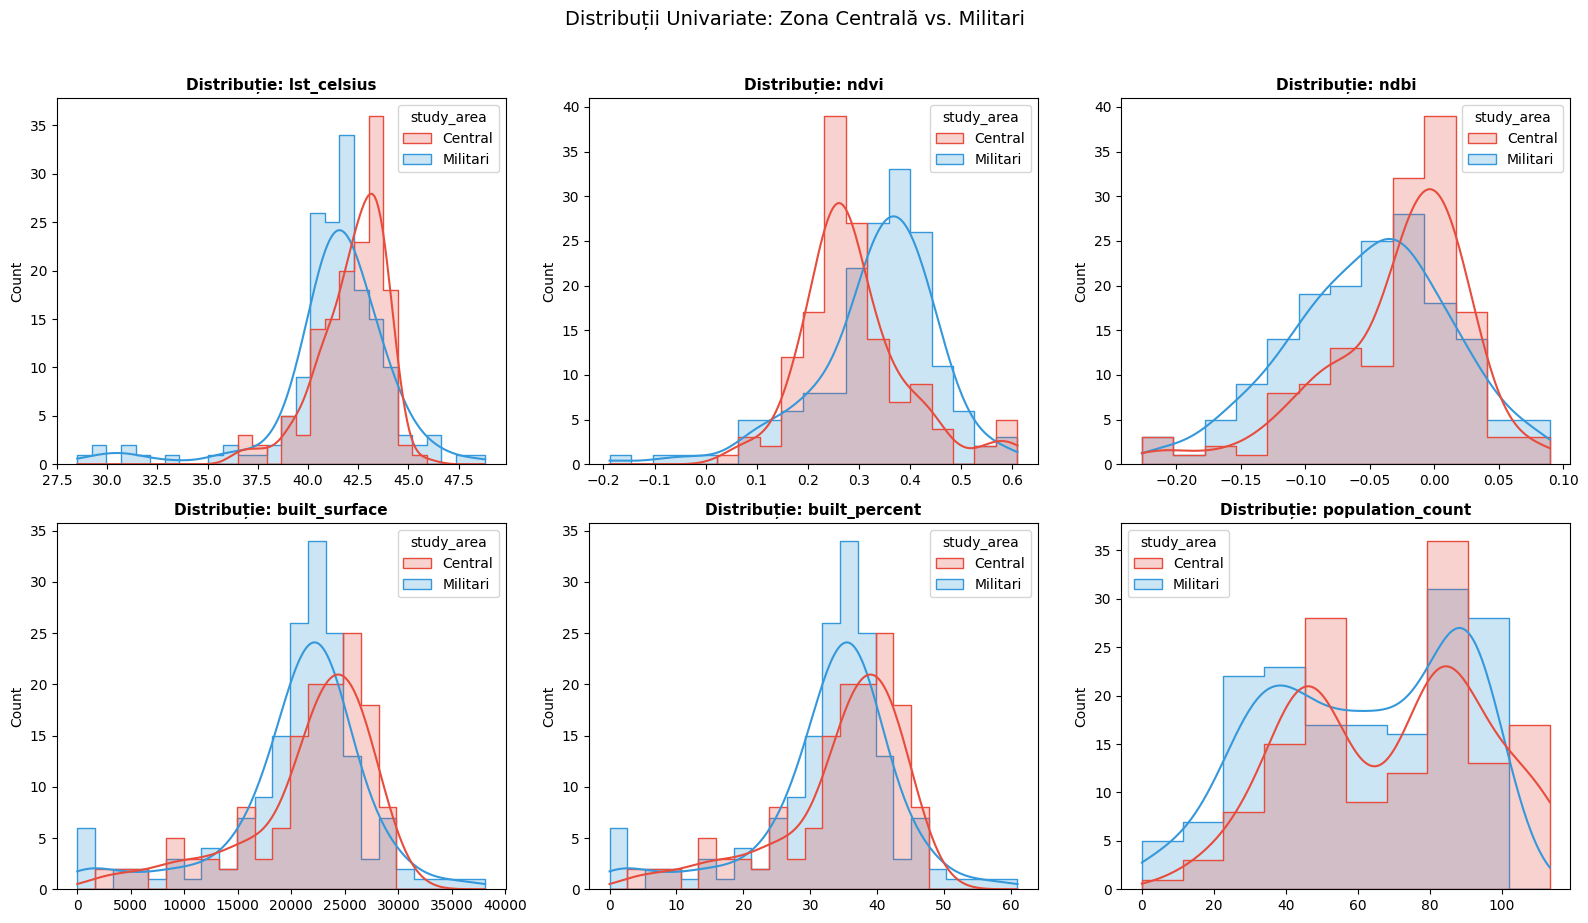

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Statistici descriptive agregate per zonă
stats_comparison = df_clean_study.groupby('study_area')[feature_cols].agg(
    ['mean', 'std', 'min', 'median', 'max', lambda x: x.skew()]
).round(2)

# Redenumim funcția anonimă pentru claritate
stats_comparison = stats_comparison.rename(columns={'<lambda_0>': 'skewness'})

print("--- STATISTICI DESCRIPTIVE COMPARATIVE ---")
display(stats_comparison)

# 2. Histograme comparative pe fiecare trăsătură
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(feature_cols):
    sns.histplot(
        data=df_clean_study, 
        x=col, 
        hue='study_area', 
        kde=True, 
        element="step",
        palette={'Central': '#e74c3c', 'Militari': '#3498db'},
        ax=axes[i]
    )
    axes[i].set_title(f"Distribuție: {col}", fontsize=11, fontweight='bold')
    axes[i].set_xlabel("")

plt.suptitle("Distribuții Univariate: Zona Centrală vs. Militari", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

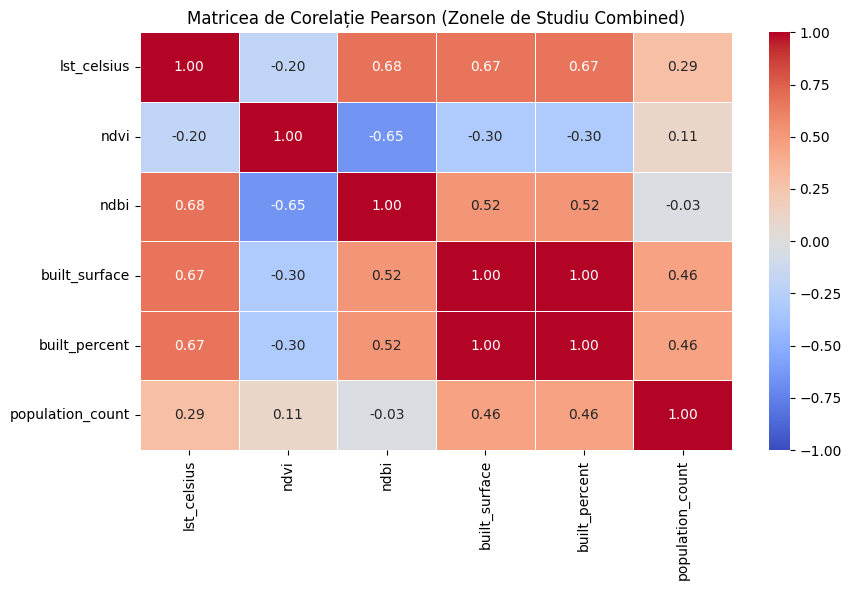

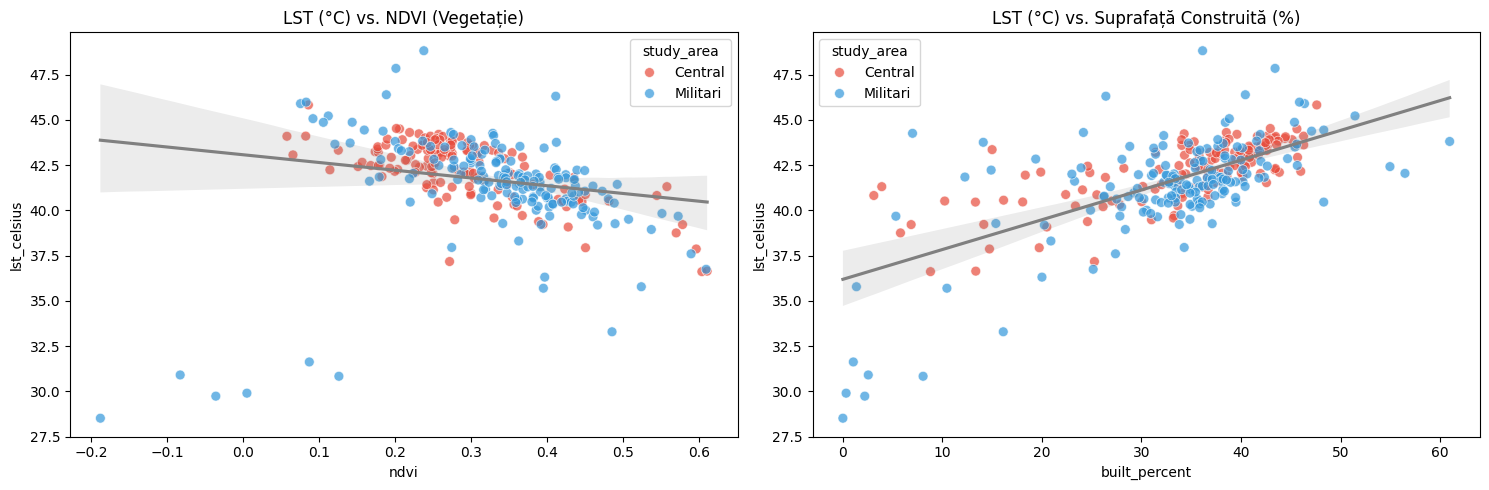

In [35]:
# 1. Heatmap Matrice de Corelație pe întregul eșantion selectat
plt.figure(figsize=(9, 6))
corr_study = df_clean_study[feature_cols].corr()

sns.heatmap(corr_study, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title("Matricea de Corelație Pearson (Zonele de Studiu Combined)", fontsize=12)
plt.tight_layout()
plt.show()

# 2. Scatter Plots Bivariate: LST vs. NDVI & LST vs. Built Percent
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Scatter 1: LST vs. NDVI (Efectul de Răcire)
sns.scatterplot(
    data=df_clean_study, x='ndvi', y='lst_celsius', 
    hue='study_area', palette={'Central': '#e74c3c', 'Militari': '#3498db'},
    alpha=0.7, s=50, ax=ax1
)
sns.regline = sns.regplot(data=df_clean_study, x='ndvi', y='lst_celsius', scatter=False, ax=ax1, color='gray')
ax1.set_title("LST (°C) vs. NDVI (Vegetație)")

# Scatter 2: LST vs. Built Percent (Efectul de Încălzire Minerală)
sns.scatterplot(
    data=df_clean_study, x='built_percent', y='lst_celsius', 
    hue='study_area', palette={'Central': '#e74c3c', 'Militari': '#3498db'},
    alpha=0.7, s=50, ax=ax2
)
sns.regplot(data=df_clean_study, x='built_percent', y='lst_celsius', scatter=False, ax=ax2, color='gray')
ax2.set_title("LST (°C) vs. Suprafață Construită (%)")

plt.tight_layout()
plt.show()

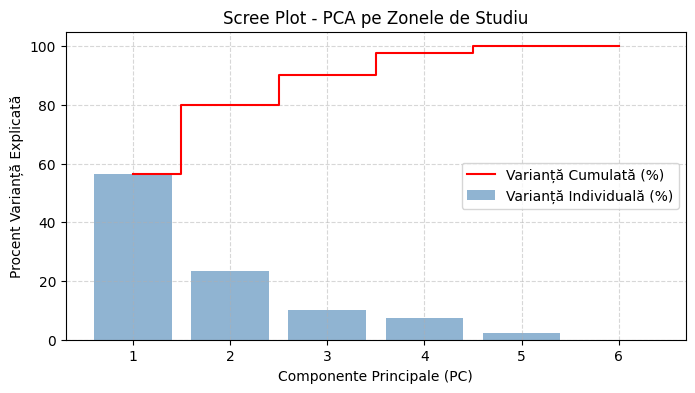

--- MATRICEA LOADINGS ---


,PC1,PC2,PC3,PC4,PC5,PC6
lst_celsius,0.448255,0.024581,0.591984,0.366355,-0.560181,1.092684e-17
ndvi,-0.265599,0.587164,0.631689,-0.091238,0.421117,9.008961e-17
ndbi,0.415338,-0.448885,0.169942,0.321655,0.702606,-1.593131e-16
built_surface,0.501992,0.189808,-0.062440,-0.453695,0.047323,7.071068e-01
built_percent,0.501992,0.189808,-0.062440,-0.453695,0.047323,-7.071068e-01
population_count,0.228094,0.617319,-0.462434,0.585081,0.103560,-1.480192e-16


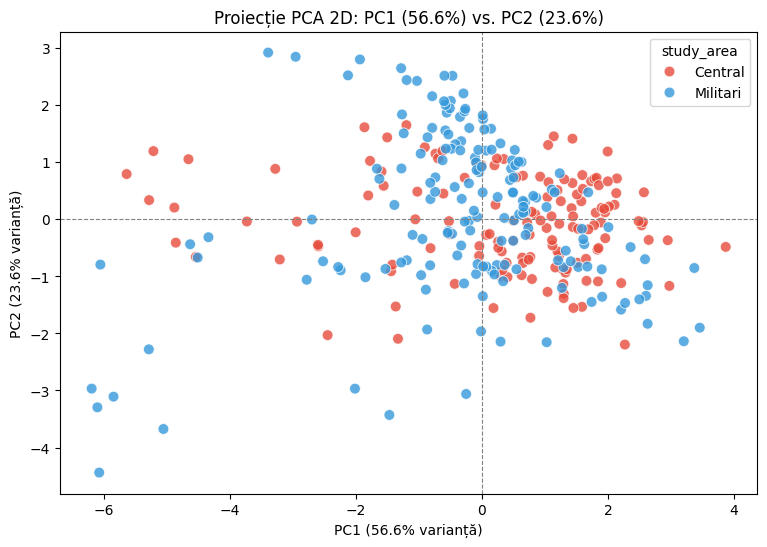

In [36]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1. Standardizarea datelor (Media=0, Varianța=1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_clean_study[feature_cols])

# 2. Aplicarea PCA
pca = PCA(n_components=len(feature_cols))
X_pca = pca.fit_transform(X_scaled)

# Adăugăm primele două componente principale în DataFrame
df_clean_study['PC1'] = X_pca[:, 0]
df_clean_study['PC2'] = X_pca[:, 1]

# 3. Scree Plot (Varianța Explicată)
var_exp = pca.explained_variance_ratio_ * 100
cum_var_exp = np.cumsum(var_exp)

plt.figure(figsize=(8, 4))
plt.bar(range(1, len(feature_cols) + 1), var_exp, alpha=0.6, color='steelblue', label='Varianță Individuală (%)')
plt.step(range(1, len(feature_cols) + 1), cum_var_exp, where='mid', color='red', label='Varianță Cumulată (%)')
plt.ylabel('Procent Varianță Explicată')
plt.xlabel('Componente Principale (PC)')
plt.xticks(range(1, len(feature_cols) + 1))
plt.title('Scree Plot - PCA pe Zonele de Studiu')
plt.legend(loc='best')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# 4. Matricea Loadings (Contribuția variabilelor în PC1 și PC2)
loadings = pd.DataFrame(
    pca.components_.T, 
    columns=[f'PC{i+1}' for i in range(len(feature_cols))],
    index=feature_cols
)

print("--- MATRICEA LOADINGS ---")
display(loadings)

# 5. Biplot / Scatter 2D: PC1 vs PC2 colorat după zona de studiu
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df_clean_study, x='PC1', y='PC2', 
    hue='study_area', palette={'Central': '#e74c3c', 'Militari': '#3498db'},
    alpha=0.8, s=60
)
plt.axhline(0, color='grey', linestyle='--', linewidth=0.8)
plt.axvline(0, color='grey', linestyle='--', linewidth=0.8)
plt.title(f"Proiecție PCA 2D: PC1 ({var_exp[0]:.1f}%) vs. PC2 ({var_exp[1]:.1f}%)")
plt.xlabel(f"PC1 ({var_exp[0]:.1f}% varianță)")
plt.ylabel(f"PC2 ({var_exp[1]:.1f}% varianță)")
plt.show()

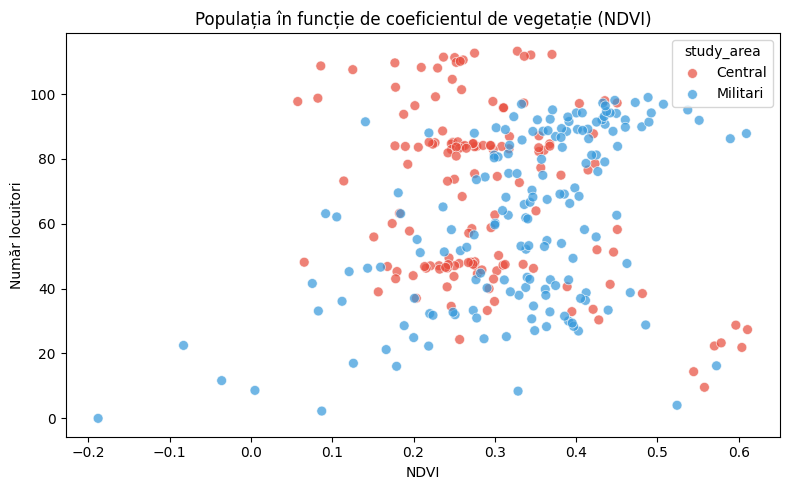

In [37]:
# Populație în funcție de NDVI
fig, ax = plt.subplots(figsize=(8, 5))

sns.scatterplot(
    data=df_clean_study,
    x='ndvi',
    y='population_count',
    hue='study_area',
    palette={'Central': '#e74c3c', 'Militari': '#3498db'},
    alpha=0.7,
    s=50,
    ax=ax
)

# sns.regplot(
#     data=df_clean_study,
#     x='ndvi',
#     y='population_count',
#     scatter=False,
#     color='gray',
#     ax=ax
# )

ax.set_title("Populația în funcție de coeficientul de vegetație (NDVI)")
ax.set_xlabel("NDVI")
ax.set_ylabel("Număr locuitori")

plt.tight_layout()
plt.show()

# CP3


In [39]:
df_clean.head()

,cell_id,time_window,zone_label,lst_celsius,ndvi,ndbi,built_surface,built_percent,population_count,geometry,is_complete
0,cell_00000,2025_summer,Periferie_Periurban,36.164025,0.625023,-0.106708,2883.262745,4.613220,1.998816,"POLYGON ((576395.486 314923.984, 576645.486 31...",True
1,cell_00001,2025_summer,Periferie_Periurban,38.474571,0.556102,-0.052520,2504.772549,4.007636,1.502125,"POLYGON ((576395.486 315173.984, 576645.486 31...",True
2,cell_00002,2025_summer,Periferie_Periurban,43.109277,0.416865,0.005692,526.847059,0.842955,0.600958,"POLYGON ((576395.486 315423.984, 576645.486 31...",True
3,cell_00003,2025_summer,Periferie_Periurban,46.424002,0.269983,0.074986,149.717647,0.239548,0.116983,"POLYGON ((576395.486 315673.984, 576645.486 31...",True
4,cell_00004,2025_summer,Periferie_Periurban,46.108377,0.261622,0.088478,1224.850980,1.959762,0.739933,"POLYGON ((576395.486 315923.984, 576645.486 31...",True


In [40]:
df_clean_study.head()

,cell_id,time_window,zone_label,lst_celsius,ndvi,ndbi,built_surface,built_percent,population_count,geometry,study_area,lst_interpolated,PC1,PC2
0,cell_03903,2025_summer,Nucleu_Urban_Central,40.322809,0.356555,-0.069063,17378.996078,27.806394,77.277099,"POLYGON ((586145.486 325423.984, 586395.486 32...",Central,False,-1.024526,0.482278
1,cell_03904,2025_summer,Nucleu_Urban_Central,37.172287,0.271738,-0.014667,15798.776471,25.278042,58.507229,"POLYGON ((586145.486 325673.984, 586395.486 32...",Central,False,-1.440219,-0.910722
2,cell_03905,2025_summer,Nucleu_Urban_Central,40.203638,0.425671,-0.100794,16340.960784,26.145537,51.981755,"POLYGON ((586145.486 325923.984, 586395.486 32...",Central,False,-1.802968,0.414754
3,cell_03906,2025_summer,Nucleu_Urban_Central,40.940320,0.300025,-0.018115,21332.384314,34.131815,62.730931,"POLYGON ((586145.486 326173.984, 586395.486 32...",Central,False,0.067062,-0.274151
4,cell_03907,2025_summer,Nucleu_Urban_Central,39.479348,0.278528,0.008528,19380.411765,31.008659,44.606966,"POLYGON ((586145.486 326423.984, 586395.486 32...",Central,False,-0.431489,-1.132418


In [41]:
!pip install -q umap-learn

In [42]:
import seaborn as sns
import networkx as nx
from scipy.spatial import procrustes

from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_regression
from sklearn.decomposition import PCA, KernelPCA
from sklearn.cross_decomposition import CCA
from sklearn.covariance import GraphicalLassoCV
from sklearn.manifold import trustworthiness
from sklearn.cluster import KMeans
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, root_mean_squared_error, mean_absolute_error, r2_score

# Daca umap-learn nu este instalat in mediul curent, decomenteaza linia de mai jos:
# !pip install -q umap-learn
import umap

sns.set_theme(style="whitegrid", font_scale=1.05)
RANDOM_STATE = 42

# 1. Pregatire GeoDataFrame
df = df_clean_study.copy()
if isinstance(df['geometry'].iloc[0], str):
    df['geometry'] = df['geometry'].apply(wkt.loads)
gdf = gpd.GeoDataFrame(df, geometry='geometry')

gdf['centroid_x'] = gdf.geometry.centroid.x
gdf['centroid_y'] = gdf.geometry.centroid.y

# 2. Definirea blocurilor de variabile (Surse)
TARGET = 'lst_celsius'
SOURCE_1_MORPH = ['built_percent', 'population_count']   # Sursa 1: Morfologie & Antropogen (2D)
SOURCE_2_SPECTRAL = ['ndvi', 'ndbi']                     # Sursa 2: Indici Spectrali (2D)
ALL_FEATURES = SOURCE_1_MORPH + SOURCE_2_SPECTRAL        # Combinat S1 + S2 (4D)
ALL_ANALYSIS_COLS = ALL_FEATURES + [TARGET]

gdf = gdf.dropna(subset=ALL_ANALYSIS_COLS).reset_index(drop=True)
print(f"Total celule valide: {len(gdf)}")
print(gdf['study_area'].value_counts())

Total celule valide: 308
study_area
Militari    166
Central     142
Name: count, dtype: int64


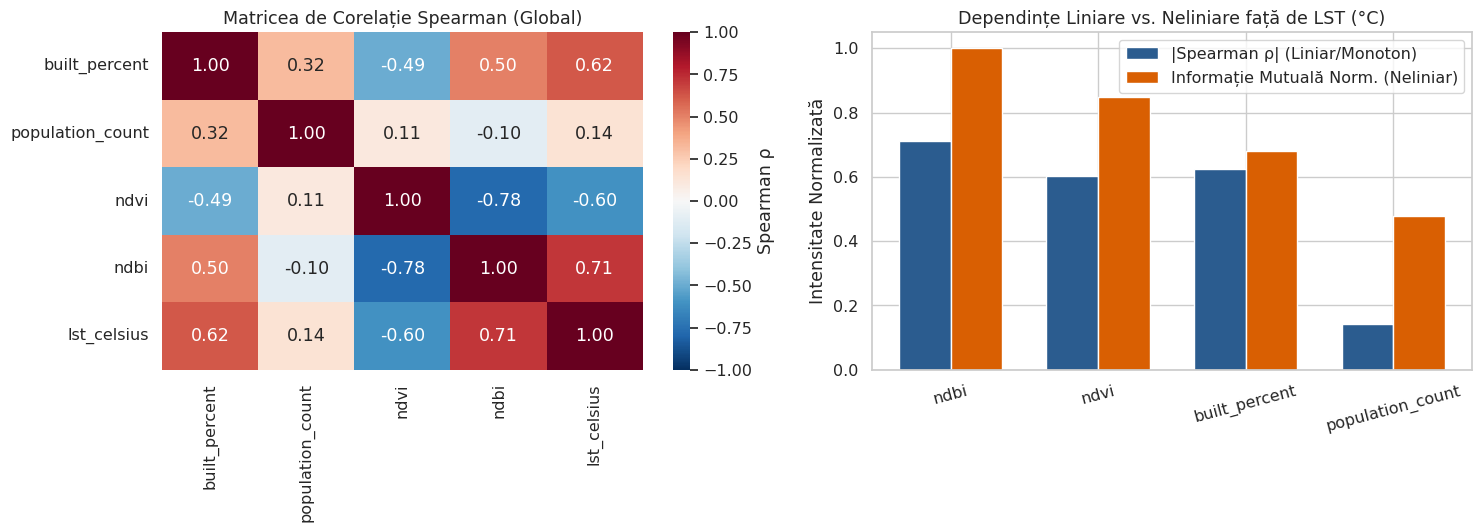

,Feature,Spearman_Signed,MI_Score
3,ndbi,0.712616,0.442971
2,ndvi,-0.602812,0.375556
0,built_percent,0.623850,0.300850
1,population_count,0.141041,0.211843


In [50]:
# 1. Matricea de corelatie Spearman
corr_matrix = gdf[ALL_ANALYSIS_COLS].corr(method='spearman')

# 2. Informatia Mutuala (MI) fata de tinta lst_celsius
X_all = gdf[ALL_FEATURES]
y_target = gdf[TARGET]

mi_scores = mutual_info_regression(X_all, y_target, random_state=RANDOM_STATE)
mi_df = pd.DataFrame({
    'Feature': ALL_FEATURES,
    'Spearman_Abs': [abs(corr_matrix.loc[col, TARGET]) for col in ALL_FEATURES],
    'Spearman_Signed': [corr_matrix.loc[col, TARGET] for col in ALL_FEATURES],
    'MI_Score': mi_scores
})
# Normalizam MI intre [0, 1] pentru comparatie vizuala cu |Spearman|
mi_df['MI_Norm'] = mi_df['MI_Score'] / mi_df['MI_Score'].max()
mi_df = mi_df.sort_values(by='MI_Score', ascending=False)

# 3. Vizualizare comparativa (2 panouri)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Panoul Stanga: Heatmap Spearman
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            ax=axes[0], cbar_kws={'label': 'Spearman ρ'})
axes[0].set_title("Matricea de Corelație Spearman (Global)")

# Panoul Dreapta: |Spearman| vs MI Normalizat
x_pos = np.arange(len(mi_df))
width = 0.35
axes[1].bar(x_pos - width/2, mi_df['Spearman_Abs'], width, label='|Spearman ρ| (Liniar/Monoton)', color='#2b5c8f')
axes[1].bar(x_pos + width/2, mi_df['MI_Norm'], width, label='Informație Mutuală Norm. (Neliniar)', color='#d95f02')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(mi_df['Feature'], rotation=15)
axes[1].set_ylabel("Intensitate Normalizată")
axes[1].set_title("Dependințe Liniare vs. Neliniare față de LST (°C)")
axes[1].legend()

plt.tight_layout()
plt.show()

display(mi_df[['Feature', 'Spearman_Signed', 'MI_Score']])

Corelația Canonică 1 (r1): 0.697
Corelația Canonică 2 (r2): 0.374


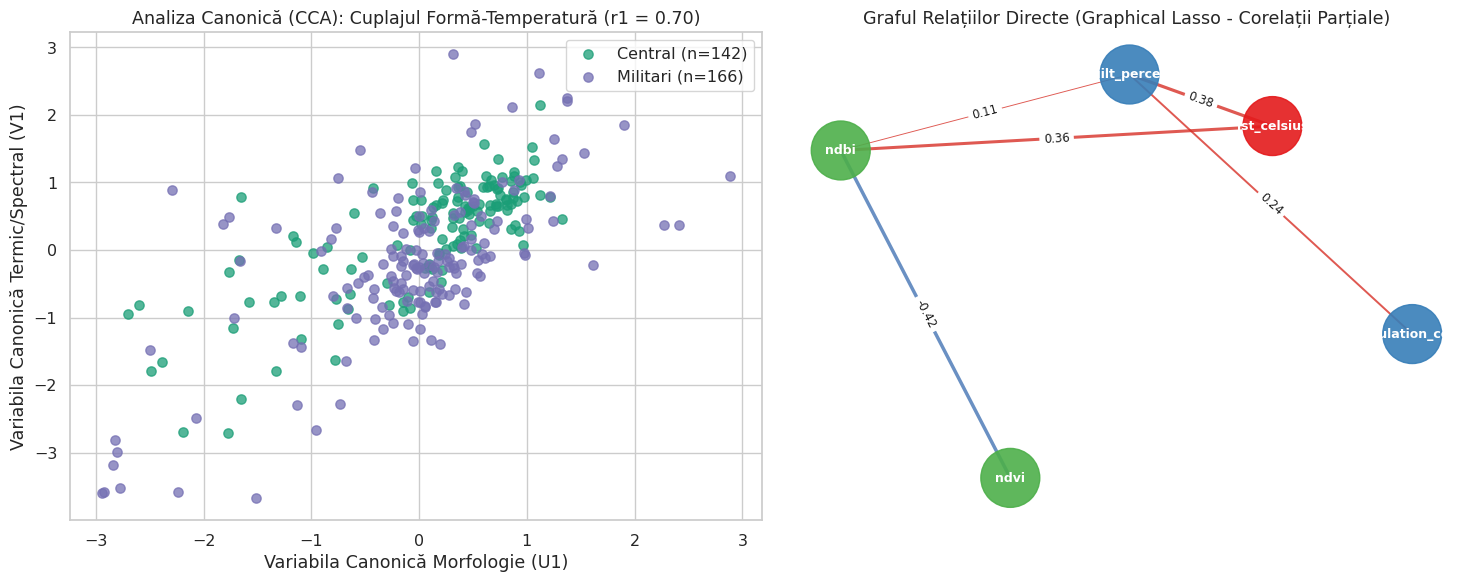

In [56]:
# --- A. CANONICAL CORRELATION ANALYSIS (CCA) ---
# Bloc X: Morfologie Urbana (Sursa 1)
# Bloc Y: Raspuns Termic & Spectral (LST + NDVI + NDBI)
X_cca_cols = ['built_percent', 'population_count']
Y_cca_cols = ['lst_celsius', 'ndvi', 'ndbi']

scaler_x = StandardScaler()
scaler_y = StandardScaler()

X_std = scaler_x.fit_transform(gdf[X_cca_cols])
Y_std = scaler_y.fit_transform(gdf[Y_cca_cols])

cca = CCA(n_components=2)
U, V = cca.fit_transform(X_std, Y_std)

# Corelatia canonica pe primele 2 componente
r1 = np.corrcoef(U[:, 0], V[:, 0])[0, 1]
r2 = np.corrcoef(U[:, 1], V[:, 1])[0, 1]
print(f"Corelația Canonică 1 (r1): {r1:.3f}")
print(f"Corelația Canonică 2 (r2): {r2:.3f}")

# --- B. GRAFUL RELATIILOR (Graphical Lasso / Corelatii Directe) ---
scaler_all = StandardScaler()
data_graph_std = scaler_all.fit_transform(gdf[ALL_ANALYSIS_COLS])

gl = GraphicalLassoCV(cv=5)
gl.fit(data_graph_std)

# Calculam matricea de corelatie partiala din matricea de precizie
precision = gl.precision_
d = np.sqrt(np.diag(precision))
partial_corr = -precision / np.outer(d, d)
np.fill_diagonal(partial_corr, 0)

# Construim graful NetworkX
G = nx.Graph()
node_colors = []
for col in ALL_ANALYSIS_COLS:
    G.add_node(col)
    if col == TARGET:
        node_colors.append('#e41a1c')      # Rosu = Tinta termica
    elif col in SOURCE_1_MORPH:
        node_colors.append('#377eb8')      # Albastru = Sursa 1 (Morfologie)
    else:
        node_colors.append('#4daf4a')      # Verde = Sursa 2 (Spectral)

# Adaugam muchii doar pentru legaturile directe semnificative
threshold = 0.08
for i in range(len(ALL_ANALYSIS_COLS)):
    for j in range(i + 1, len(ALL_ANALYSIS_COLS)):
        weight = partial_corr[i, j]
        if abs(weight) > threshold:
            G.add_edge(ALL_ANALYSIS_COLS[i], ALL_ANALYSIS_COLS[j], weight=weight)

# --- VIZUALIZARE COMBINATA (CCA Scatter + Graf) ---
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Stanga: Proiectia CCA U1 vs V1 colorata dupa zona de studiu
for area, color in zip(gdf['study_area'].unique(), ['#1b9e77', '#7570b3']):
    mask = gdf['study_area'] == area
    axes[0].scatter(U[mask, 0], V[mask, 0], label=f"{area} (n={mask.sum()})", alpha=0.75, s=45, c=color)
axes[0].set_xlabel(f"Variabila Canonică Morfologie (U1)")
axes[0].set_ylabel(f"Variabila Canonică Termic/Spectral (V1)")
axes[0].set_title(f"Analiza Canonică (CCA): Cuplajul Formă-Temperatură (r1 = {r1:.2f})")
axes[0].legend()

# Dreapta: Graful Relatiilor Directe
pos = nx.spring_layout(G, seed=RANDOM_STATE, k=1.5)
edges = G.edges(data=True)
edge_widths = [abs(d['weight']) * 6 for _, _, d in edges]
edge_colors = ['#d73027' if d['weight'] > 0 else '#4575b4' for _, _, d in edges]

nx.draw_networkx_nodes(G, pos, ax=axes[1], node_color=node_colors, node_size=1800, alpha=0.9)
nx.draw_networkx_labels(G, pos, ax=axes[1], font_size=9, font_weight='bold', font_color='white')
nx.draw_networkx_edges(G, pos, ax=axes[1], width=edge_widths, edge_color=edge_colors, alpha=0.8)

# Etichete pe muchii cu valoarea corelatiei partiale
edge_labels = {(u, v): f"{d['weight']:.2f}" for u, v, d in edges}
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, ax=axes[1], font_size=8.5)
axes[1].set_title("Graful Relațiilor Directe (Graphical Lasso - Corelații Parțiale)")
axes[1].axis('off')

plt.tight_layout()
plt.show()

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


=== 1. METRICI COMPARATIVE PE SURSE ȘI COMBINAT ===


,Sursă Date,Metodă,Varianță Explicată,Eroare Reconstrucție (MSE),Trustworthiness (k=10),Aliniere cu LST (|r| max)
0,"Sursa 1: Satelit Optic (ndvi, ndbi) [2D -> 1D]",PCA (Baseline Liniar),82.72%,0.1728,0.9134,0.482
1,"Sursa 1: Satelit Optic (ndvi, ndbi) [2D -> 1D]",KernelPCA (Neliniar RBF),N/A (Kernel),0.3504,0.8419,0.480
2,"Sursa 1: Satelit Optic (ndvi, ndbi) [2D -> 1D]",UMAP (Manifold Neliniar),N/A (Manifold),NaN,0.9834,0.551
3,Sursa 2: Clădiri/Vector (built_percent) [1D na...,Reprezentare Directă (1D nativ),100.00%,0.0000,1.0000,0.670
4,Sursa 3: Demografie (population_count) [1D nativ],Reprezentare Directă (1D nativ),100.00%,0.0000,1.0000,0.287
5,Sursa 4: Termic Satelitar (lst_celsius) [1D na...,Reprezentare Directă (1D nativ),100.00%,0.0000,1.0000,1.000
6,Combinat Predictori (S1+S2+S3) [4D -> 2D],PCA (Baseline Liniar),82.96%,0.1704,0.9620,0.663
7,Combinat Predictori (S1+S2+S3) [4D -> 2D],KernelPCA (Neliniar RBF),N/A (Kernel),0.3856,0.8847,0.363
8,Combinat Predictori (S1+S2+S3) [4D -> 2D],UMAP (Manifold Neliniar),N/A (Manifold),NaN,0.9811,0.580



=== 2. PONDERILE EXACTE ALE AXELOR PCA (Loadings) ===


,PCA Dim 1 (X),PCA Dim 2 (Y)
built_percent,-0.537,0.397
population_count,0.618,-0.233
ndvi,0.548,0.406
ndbi,0.171,0.790



=== 3. CORELAȚIA AXELOR CU VARIABILELE ORIGINALE (Spearman ρ) ===

--- Semantica Axelor: PCA ---


,Axa X (Dim 1),Axa Y (Dim 2)
built_percent,0.785,0.258
population_count,0.140,0.913
ndvi,-0.842,0.387
ndbi,0.882,-0.377
lst_celsius,0.766,-0.052



--- Semantica Axelor: KernelPCA ---


,Axa X (Dim 1),Axa Y (Dim 2)
built_percent,-0.413,-0.617
population_count,0.452,-0.748
ndvi,0.768,0.348
ndbi,-0.820,-0.263
lst_celsius,-0.546,-0.444



--- Semantica Axelor: UMAP ---


,Axa X (Dim 1),Axa Y (Dim 2)
built_percent,0.712,0.247
population_count,0.055,0.856
ndvi,-0.840,0.230
ndbi,0.850,-0.190
lst_celsius,0.743,0.079


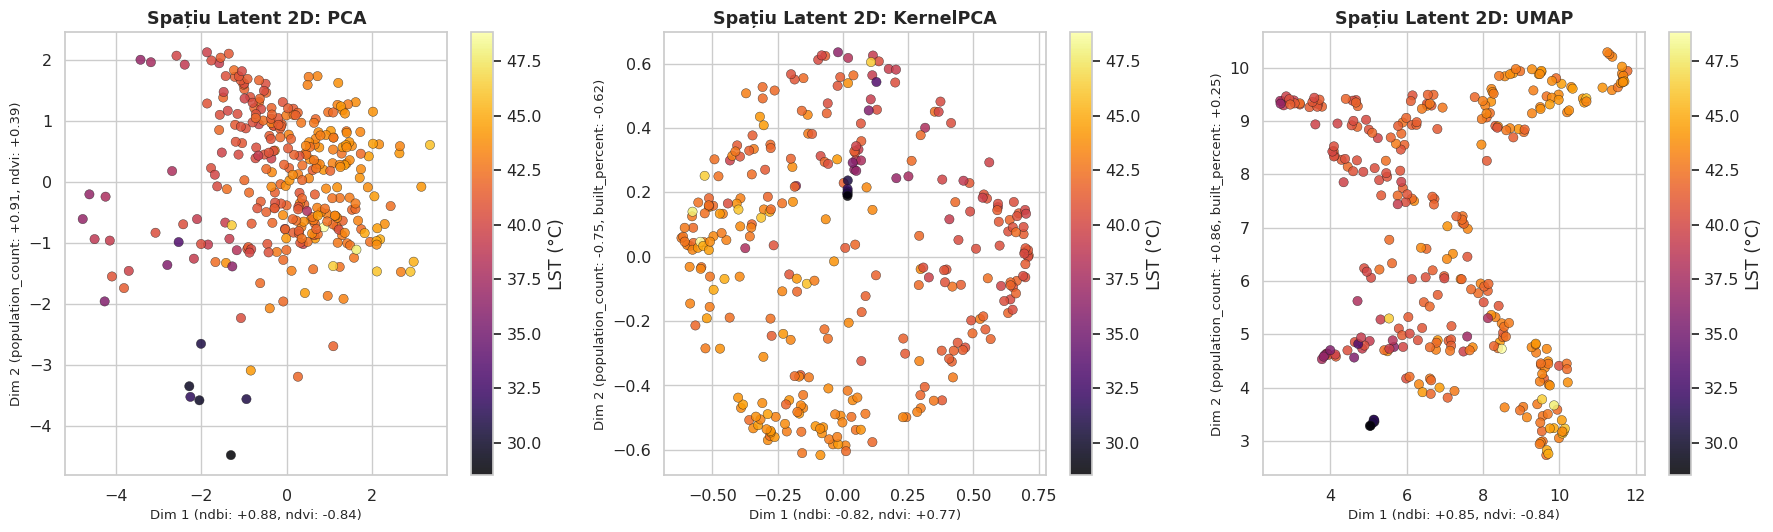

In [48]:
# Definirea pe cele 4 SURSE REALE din proiect + Combinat (fara data leakage pe X)
real_sources = {
    "Sursa 1: Satelit Optic (ndvi, ndbi) [2D -> 1D]": (['ndvi', 'ndbi'], 1),
    "Sursa 2: Clădiri/Vector (built_percent) [1D nativ]": (['built_percent'], 1),
    "Sursa 3: Demografie (population_count) [1D nativ]": (['population_count'], 1),
    "Sursa 4: Termic Satelitar (lst_celsius) [1D nativ]": (['lst_celsius'], 1),
    "Combinat Predictori (S1+S2+S3) [4D -> 2D]": (['ndvi', 'ndbi', 'built_percent', 'population_count'], 2)
}

latent_results = []
embeddings_store = {}
y_lst = gdf[TARGET].values

for set_name, (cols, n_comp) in real_sources.items():
    X_scaled = StandardScaler().fit_transform(gdf[cols].values)
    
    # Cazul surselor unidimensionale (1D nativ - nu se face compresie)
    if X_scaled.shape[1] == 1:
        trust_1d = trustworthiness(X_scaled, X_scaled, n_neighbors=10)
        corr_lst = abs(np.corrcoef(X_scaled[:, 0], y_lst)[0, 1])
        latent_results.append({
            'Sursă Date': set_name,
            'Metodă': 'Reprezentare Directă (1D nativ)',
            'Varianță Explicată': '100.00%',
            'Eroare Reconstrucție (MSE)': 0.0000,
            'Trustworthiness (k=10)': round(trust_1d, 4),
            'Aliniere cu LST (|r| max)': round(corr_lst, 3)
        })
        continue

    # --- 1. BASELINE: PCA ---
    pca = PCA(n_components=n_comp, random_state=RANDOM_STATE)
    Z_pca = pca.fit_transform(X_scaled)
    X_rec_pca = pca.inverse_transform(Z_pca)
    corr_pca = max(abs(np.corrcoef(Z_pca[:, i], y_lst)[0, 1]) for i in range(n_comp))
    
    latent_results.append({
        'Sursă Date': set_name,
        'Metodă': 'PCA (Baseline Liniar)',
        'Varianță Explicată': f"{np.sum(pca.explained_variance_ratio_)*100:.2f}%",
        'Eroare Reconstrucție (MSE)': round(mean_squared_error(X_scaled, X_rec_pca), 4),
        'Trustworthiness (k=10)': round(trustworthiness(X_scaled, Z_pca, n_neighbors=10), 4),
        'Aliniere cu LST (|r| max)': round(corr_pca, 3)
    })

    # --- 2. KernelPCA (RBF) ---
    kpca = KernelPCA(n_components=n_comp, kernel='rbf', gamma=0.25,
                     fit_inverse_transform=True, alpha=0.1, random_state=RANDOM_STATE)
    Z_kpca = kpca.fit_transform(X_scaled)
    X_rec_kpca = kpca.inverse_transform(Z_kpca)
    corr_kpca = max(abs(np.corrcoef(Z_kpca[:, i], y_lst)[0, 1]) for i in range(n_comp))
    
    latent_results.append({
        'Sursă Date': set_name,
        'Metodă': 'KernelPCA (Neliniar RBF)',
        'Varianță Explicată': 'N/A (Kernel)',
        'Eroare Reconstrucție (MSE)': round(mean_squared_error(X_scaled, X_rec_kpca), 4),
        'Trustworthiness (k=10)': round(trustworthiness(X_scaled, Z_kpca, n_neighbors=10), 4),
        'Aliniere cu LST (|r| max)': round(corr_kpca, 3)
    })

    # --- 3. UMAP ---
    Z_umap = umap.UMAP(n_components=n_comp, n_neighbors=15, min_dist=0.1, random_state=RANDOM_STATE).fit_transform(X_scaled)
    corr_umap = max(abs(np.corrcoef(Z_umap[:, i], y_lst)[0, 1]) for i in range(n_comp))
    
    latent_results.append({
        'Sursă Date': set_name,
        'Metodă': 'UMAP (Manifold Neliniar)',
        'Varianță Explicată': 'N/A (Manifold)',
        'Eroare Reconstrucție (MSE)': np.nan,
        'Trustworthiness (k=10)': round(trustworthiness(X_scaled, Z_umap, n_neighbors=10), 4),
        'Aliniere cu LST (|r| max)': round(corr_umap, 3)
    })

    if "Combinat" in set_name:
        embeddings_store['Combinat'] = {'PCA': Z_pca, 'KernelPCA': Z_kpca, 'UMAP': Z_umap}
        pca_comb_model = pca

print("=== 1. METRICI COMPARATIVE PE SURSE ȘI COMBINAT ===")
display(pd.DataFrame(latent_results))

# === 2. EXPLICAREA SEMANTICĂ A AXELOR PENTRU CELE 3 METODE ===
print("\n=== 2. PONDERILE EXACTE ALE AXELOR PCA (Loadings) ===")
df_loadings = pd.DataFrame(
    pca_comb_model.components_.T,
    index=ALL_FEATURES,
    columns=['PCA Dim 1 (X)', 'PCA Dim 2 (Y)']
)
display(df_loadings.round(3))

print("\n=== 3. CORELAȚIA AXELOR CU VARIABILELE ORIGINALE (Spearman ρ) ===")
axis_labels_auto = {}  # Stocam etichetele explicative generate automat pentru grafice

for method_name, Z_emb in embeddings_store['Combinat'].items():
    corr_x = {c: pd.Series(Z_emb[:, 0]).corr(gdf[c], method='spearman') for c in ALL_FEATURES + [TARGET]}
    corr_y = {c: pd.Series(Z_emb[:, 1]).corr(gdf[c], method='spearman') for c in ALL_FEATURES + [TARGET]}
    
    df_ax = pd.DataFrame({'Axa X (Dim 1)': corr_x, 'Axa Y (Dim 2)': corr_y})
    print(f"\n--- Semantica Axelor: {method_name} ---")
    display(df_ax.round(3))
    
    # Construim automat eticheta descriptiva cu top 2 variabile (doar din predictori)
    top_x = sorted(ALL_FEATURES, key=lambda c: abs(corr_x[c]), reverse=True)[:2]
    top_y = sorted(ALL_FEATURES, key=lambda c: abs(corr_y[c]), reverse=True)[:2]
    
    label_x = f"Dim 1 ({', '.join([f'{c}: {corr_x[c]:+.2f}' for c in top_x])})"
    label_y = f"Dim 2 ({', '.join([f'{c}: {corr_y[c]:+.2f}' for c in top_y])})"
    axis_labels_auto[method_name] = (label_x, label_y)

# === 4. VIZUALIZARE CU AXE ETICHETATE AUTOMAT ===
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, method_name in zip(axes, ['PCA', 'KernelPCA', 'UMAP']):
    Z_emb = embeddings_store['Combinat'][method_name]
    lx, ly = axis_labels_auto[method_name]
    
    sc = ax.scatter(Z_emb[:, 0], Z_emb[:, 1], c=y_lst, cmap='inferno', s=45, alpha=0.85, edgecolors='k', linewidth=0.3)
    ax.set_title(f"Spațiu Latent 2D: {method_name}", fontweight='bold')
    ax.set_xlabel(lx, fontsize=9.5)
    ax.set_ylabel(ly, fontsize=9.5)
    plt.colorbar(sc, ax=ax, label='LST (°C)')

plt.tight_layout()
plt.show()

In [46]:
X_comb_scaled = StandardScaler().fit_transform(gdf[ALL_FEATURES])
X1_comb = StandardScaler().fit_transform(gdf[SOURCE_1_MORPH])
X2_comb = StandardScaler().fit_transform(gdf[SOURCE_2_SPECTRAL])

seeds = [0, 7, 13, 21, 42, 77, 99, 123, 256, 999]

# --- TEST 1: STABILITATE LA SEED-URI (Disparitate Procrustes fata de seed=42) ---
ref_pca = PCA(n_components=2, random_state=42).fit_transform(X_comb_scaled)
ref_kpca = KernelPCA(n_components=2, kernel='rbf', gamma=0.25, random_state=42).fit_transform(X_comb_scaled)
ref_umap = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=42).fit_transform(X_comb_scaled)

seed_stability = []
for s in seeds:
    z_p = PCA(n_components=2, random_state=s).fit_transform(X_comb_scaled)
    z_k = KernelPCA(n_components=2, kernel='rbf', gamma=0.25, random_state=s).fit_transform(X_comb_scaled)
    z_u = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=s).fit_transform(X_comb_scaled)
    
    _, _, disp_p = procrustes(ref_pca, z_p)
    _, _, disp_k = procrustes(ref_kpca, z_k)
    _, _, disp_u = procrustes(ref_umap, z_u)
    
    seed_stability.append({'Seed': s, 'PCA': disp_p, 'KernelPCA': disp_k, 'UMAP': disp_u})

df_seed_stab = pd.DataFrame(seed_stability)

# --- TEST 2: STABILITATE LA SUB-ESANTIOANE (80% din celule, 10 iteratii) ---
rng = np.random.default_rng(RANDOM_STATE)
subsample_stability = []

for i in range(10):
    idx = np.sort(rng.choice(len(X_comb_scaled), size=int(0.8 * len(X_comb_scaled)), replace=False))
    
    z_p_sub = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_comb_scaled[idx])
    z_k_sub = KernelPCA(n_components=2, kernel='rbf', gamma=0.25, random_state=RANDOM_STATE).fit_transform(X_comb_scaled[idx])
    z_u_sub = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=RANDOM_STATE).fit_transform(X_comb_scaled[idx])
    
    _, _, disp_p_sub = procrustes(ref_pca[idx], z_p_sub)
    _, _, disp_k_sub = procrustes(ref_kpca[idx], z_k_sub)
    _, _, disp_u_sub = procrustes(ref_umap[idx], z_u_sub)
    
    subsample_stability.append({'Iter': i, 'PCA': disp_p_sub, 'KernelPCA': disp_k_sub, 'UMAP': disp_u_sub})

df_sub_stab = pd.DataFrame(subsample_stability)

# --- TEST 3: STABILITATE PE SUB-REGIUNI (Central vs. Militari) ---
regime_rows = []
for regime in ['Global (Toate)', 'Central', 'Militari']:
    mask = np.ones(len(gdf), dtype=bool) if regime == 'Global (Toate)' else (gdf['study_area'] == regime).values
    X_reg = StandardScaler().fit_transform(gdf.loc[mask, ALL_FEATURES])
    y_reg = gdf.loc[mask, TARGET].values
    
    pca_r = PCA(n_components=2, random_state=RANDOM_STATE).fit(X_reg)
    z_p_r = pca_r.transform(X_reg)
    z_u_r = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=RANDOM_STATE).fit_transform(X_reg)
    
    regime_rows.append({
        'Regim / Sub-perioadă': regime,
        'N celule': mask.sum(),
        'PCA Var. Explicată (%)': f"{np.sum(pca_r.explained_variance_ratio_)*100:.2f}%",
        'PCA Trustworthiness': round(trustworthiness(X_reg, z_p_r, n_neighbors=10), 4),
        'UMAP Trustworthiness': round(trustworthiness(X_reg, z_u_r, n_neighbors=10), 4),
        'Corr(|PC1|, LST)': round(abs(np.corrcoef(z_p_r[:, 0], y_reg)[0, 1]), 3)
    })

df_regime_stab = pd.DataFrame(regime_rows)

# Rezumatul stabilitatii
summary_stab = pd.DataFrame({
    'Metodă': ['PCA (Baseline)', 'KernelPCA (RBF)', 'UMAP'],
    'Disparitate Seed-uri (Medie ± Std)': [
        f"{df_seed_stab['PCA'].mean():.4f} ± {df_seed_stab['PCA'].std():.4f}",
        f"{df_seed_stab['KernelPCA'].mean():.4f} ± {df_seed_stab['KernelPCA'].std():.4f}",
        f"{df_seed_stab['UMAP'].mean():.4f} ± {df_seed_stab['UMAP'].std():.4f}"
    ],
    'Disparitate Sub-eșantion 80% (Medie ± Std)': [
        f"{df_sub_stab['PCA'].mean():.4f} ± {df_sub_stab['PCA'].std():.4f}",
        f"{df_sub_stab['KernelPCA'].mean():.4f} ± {df_sub_stab['KernelPCA'].std():.4f}",
        f"{df_sub_stab['UMAP'].mean():.4f} ± {df_sub_stab['UMAP'].std():.4f}"
    ]
})

print("=== 1. STABILITATE GEOMETRICĂ (Disparitate Procrustes: 0 = Perfect stabil) ===")
display(summary_stab)
print("\n=== 2. STABILITATE PE SUB-REGIUNI (Central vs. Militari) ===")
display(df_regime_stab)

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr

=== 1. STABILITATE GEOMETRICĂ (Disparitate Procrustes: 0 = Perfect stabil) ===


,Metodă,Disparitate Seed-uri (Medie ± Std),Disparitate Sub-eșantion 80% (Medie ± Std)
0,PCA (Baseline),0.0000 ± 0.0000,0.0004 ± 0.0003
1,KernelPCA (RBF),0.0000 ± 0.0000,0.0024 ± 0.0020
2,UMAP,0.0304 ± 0.0205,0.0638 ± 0.0200



=== 2. STABILITATE PE SUB-REGIUNI (Central vs. Militari) ===


,Regim / Sub-perioadă,N celule,PCA Var. Explicată (%),PCA Trustworthiness,UMAP Trustworthiness,"Corr(|PC1|, LST)"
0,Global (Toate),308,82.96%,0.9620,0.9811,0.663
1,Central,142,92.63%,0.9806,0.9807,0.789
2,Militari,166,80.66%,0.9589,0.9743,0.107


,Model,Protocol,RMSE (°C),MAE (°C),R2
0,Baseline 1: Ridge (Liniar - Sursa 1),Spatial Block CV (6-Fold),2.037 ± 0.959,1.527 ± 0.621,-0.213 ± 0.639
1,Baseline 2: Random Forest (Neliniar - Sursa 1),Spatial Block CV (6-Fold),2.279 ± 1.181,1.631 ± 0.734,-0.484 ± 0.812
2,Baseline 1: Ridge (Liniar - Sursa 1),Cross-Zone (Central -> Militari),2.440,1.742,0.319
3,Baseline 2: Random Forest (Neliniar - Sursa 1),Cross-Zone (Central -> Militari),2.746,1.864,0.137
4,Baseline 1: Ridge (Liniar - Sursa 1),Cross-Zone (Militari -> Central),1.524,1.139,0.147
5,Baseline 2: Random Forest (Neliniar - Sursa 1),Cross-Zone (Militari -> Central),1.859,1.407,-0.269


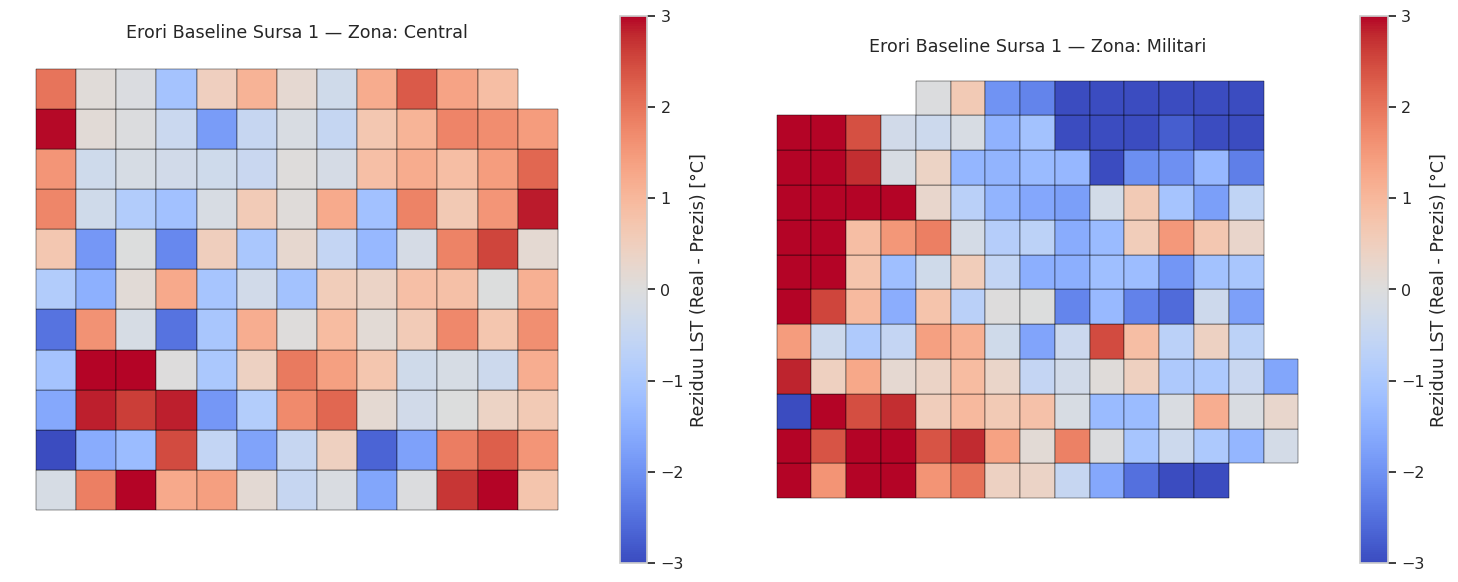

In [44]:
# 1. DEFINIREA SPLIT-URILOR SPATIALE (Fara Data Leakage)
# Cream 6 blocuri spatiale compacte (3 in Centru, 3 in Periferie/Militari) folosind KMeans pe coordonate
gdf['spatial_block'] = -1
block_offset = 0

for area in gdf['study_area'].unique():
    mask = gdf['study_area'] == area
    coords = gdf.loc[mask, ['centroid_x', 'centroid_y']]
    kmeans = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
    gdf.loc[mask, 'spatial_block'] = kmeans.fit_predict(coords) + block_offset
    block_offset += 3

# Salvam split-urile spatiale pentru reproductibilitate in CP4
gdf[['cell_id', 'study_area', 'spatial_block']].to_csv("spatial_splits_CP3.csv", index=False)

# 2. DEFINIREA MODELELOR DE BASELINE PE O SINGURA SURSA (Sursa 1: Morfologie)
X_s1 = gdf[SOURCE_1_MORPH]
y = gdf[TARGET]
groups = gdf['spatial_block']

models = {
    "Baseline 1: Ridge (Liniar - Sursa 1)": Pipeline([
        ('scaler', StandardScaler()),
        ('model', Ridge(alpha=1.0))
    ]),
    "Baseline 2: Random Forest (Neliniar - Sursa 1)": Pipeline([
        ('scaler', StandardScaler()),
        ('model', RandomForestRegressor(n_estimators=200, max_depth=6, random_state=RANDOM_STATE))
    ])
}

# 3. EVALUARE SCENARIUL 1: Spatial Block Cross-Validation (GroupKFold)
gkf = GroupKFold(n_splits=6)
results = []

# Stocam predictiile out-of-fold pentru analiza reziduurilor
oof_preds_rf = np.zeros(len(gdf))

for name, pipe in models.items():
    rmses, maes, r2s = [], [], []
    for train_idx, test_idx in gkf.split(X_s1, y, groups):
        pipe.fit(X_s1.iloc[train_idx], y.iloc[train_idx])
        preds = pipe.predict(X_s1.iloc[test_idx])
        
        if "Random Forest" in name:
            oof_preds_rf[test_idx] = preds
            
        rmses.append(root_mean_squared_error(y.iloc[test_idx], preds))
        maes.append(mean_absolute_error(y.iloc[test_idx], preds))
        r2s.append(r2_score(y.iloc[test_idx], preds))
        
    results.append({
        'Model': name,
        'Protocol': 'Spatial Block CV (6-Fold)',
        'RMSE (°C)': f"{np.mean(rmses):.3f} ± {np.std(rmses):.3f}",
        'MAE (°C)': f"{np.mean(maes):.3f} ± {np.std(maes):.3f}",
        'R2': f"{np.mean(r2s):.3f} ± {np.std(r2s):.3f}"
    })

# 4. EVALUARE SCENARIUL 2: Cross-Zone Transfer (Antrenare pe o zona -> Test pe cealalta)
areas = gdf['study_area'].unique()
if len(areas) == 2:
    for train_area, test_area in [(areas[0], areas[1]), (areas[1], areas[0])]:
        tr_mask = gdf['study_area'] == train_area
        te_mask = gdf['study_area'] == test_area
        
        for name, pipe in models.items():
            pipe.fit(X_s1[tr_mask], y[tr_mask])
            preds = pipe.predict(X_s1[te_mask])
            results.append({
                'Model': name,
                'Protocol': f"Cross-Zone ({train_area} -> {test_area})",
                'RMSE (°C)': f"{root_mean_squared_error(y[te_mask], preds):.3f}",
                'MAE (°C)': f"{mean_absolute_error(y[te_mask], preds):.3f}",
                'R2': f"{r2_score(y[te_mask], preds):.3f}"
            })

results_df = pd.DataFrame(results)
display(results_df)

# 5. VIZUALIZAREA HARTII DE REZIDUURI SI A BLOCURILOR SPATIALE
gdf['residual_rf'] = gdf[TARGET] - oof_preds_rf

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for idx, area in enumerate(areas):
    sub = gdf[gdf['study_area'] == area]
    sub.plot(column='residual_rf', cmap='coolwarm', vmin=-3, vmax=3,
             legend=True, ax=axes[idx], edgecolor='black', linewidth=0.3,
             legend_kwds={'label': 'Reziduu LST (Real - Prezis) [°C]'})
    axes[idx].set_title(f"Erori Baseline Sursa 1 — Zona: {area}")
    axes[idx].set_axis_off()

plt.tight_layout()
plt.show()

## Comparatie GHS-BUILT-S 2020 și 2025 (OPTIONAL)

In [20]:
import ee
import pandas as pd
import json

ee.Initialize(project='earth-engine-uhi')

# 1. Încărcăm imaginile GHSL pentru cei doi ani
ghsl_2020 = (
    ee.Image('JRC/GHSL/P2023A/GHS_BUILT_S/2020')
    .select('built_surface')
)

ghsl_2025 = (
    ee.Image('JRC/GHSL/P2023A/GHS_BUILT_S/2025')
    .select('built_surface')
)

# 2. Pregătim grila
batch_size = 500
records = []
total_cells = len(gdf_grid_wgs84)

# 3. Extragem valorile pentru fiecare celulă
for i in range(0, total_cells, batch_size):

    batch_gdf = gdf_grid_wgs84.iloc[i:i + batch_size]

    geojson_features = json.loads(
        batch_gdf[['cell_id', 'geometry']].to_json()
    )['features']

    ee_fc = ee.FeatureCollection(geojson_features)

    # GHSL 2020
    reduced_2020 = ghsl_2020.reduceRegions(
        collection=ee_fc,
        reducer=ee.Reducer.mean(),
        scale=100
    )

    # GHSL 2025
    reduced_2025 = ghsl_2025.reduceRegions(
        collection=ee_fc,
        reducer=ee.Reducer.mean(),
        scale=100
    )

    feats_2020 = reduced_2020.getInfo()['features']
    feats_2025 = reduced_2025.getInfo()['features']

    # Asociem valorile după cell_id
    values_2020 = {
        f['properties']['cell_id']: f['properties'].get('mean')
        for f in feats_2020
    }

    values_2025 = {
        f['properties']['cell_id']: f['properties'].get('mean')
        for f in feats_2025
    }

    for cell_id in batch_gdf['cell_id']:

        value_2020 = values_2020.get(cell_id)
        value_2025 = values_2025.get(cell_id)

        records.append({
            'cell_id': cell_id,
            'built_2020': value_2020,
            'built_2025': value_2025
        })

    print(
        f'Progres: {min(i + batch_size, total_cells)} '
        f'/ {total_cells} celule'
    )

# 4. Construim DataFrame-ul
df_ghsl_comparison = pd.DataFrame(records)

# 5. Calculăm diferența absolută și procentuală
df_ghsl_comparison['difference'] = (
    df_ghsl_comparison['built_2025']
    - df_ghsl_comparison['built_2020']
)

df_ghsl_comparison['difference_percent'] = (
    df_ghsl_comparison['difference']
    / df_ghsl_comparison['built_2020'].replace(0, float('nan'))
) * 100

display(df_ghsl_comparison.head())

print('\\nStatistici GHSL 2020:')
print(df_ghsl_comparison['built_2020'].describe())

print('\\nStatistici GHSL 2025:')
print(df_ghsl_comparison['built_2025'].describe())

print('\\nStatistici diferențe:')
print(df_ghsl_comparison['difference'].describe())

Progres: 500 / 9009 celule
Progres: 1000 / 9009 celule
Progres: 1500 / 9009 celule
Progres: 2000 / 9009 celule
Progres: 2500 / 9009 celule
Progres: 3000 / 9009 celule
Progres: 3500 / 9009 celule
Progres: 4000 / 9009 celule
Progres: 4500 / 9009 celule
Progres: 5000 / 9009 celule
Progres: 5500 / 9009 celule
Progres: 6000 / 9009 celule
Progres: 6500 / 9009 celule
Progres: 7000 / 9009 celule
Progres: 7500 / 9009 celule
Progres: 8000 / 9009 celule
Progres: 8500 / 9009 celule
Progres: 9000 / 9009 celule
Progres: 9009 / 9009 celule


,cell_id,built_2020,built_2025,difference,difference_percent
0,cell_00000,452.729064,452.729064,0.000000,0.000000
1,cell_00001,402.214736,402.214736,0.000000,0.000000
2,cell_00002,85.190869,85.190869,0.000000,0.000000
3,cell_00003,23.494154,23.494154,0.000000,0.000000
4,cell_00004,184.980570,202.290803,17.310233,9.357866


\nStatistici GHSL 2020:
count    9009.000000
mean     1648.162884
std      1581.163879
min         0.000000
25%        41.188013
50%      1264.627184
75%      3117.630273
max      9770.273567
Name: built_2020, dtype: float64
\nStatistici GHSL 2025:
count    9009.000000
mean     1687.996439
std      1571.456814
min         0.000000
25%        72.703567
50%      1364.602833
75%      3135.462346
max      9770.273567
Name: built_2025, dtype: float64
\nStatistici diferențe:
count    9.009000e+03
mean     3.983356e+01
std      1.403459e+02
min     -4.547474e-13
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      2.629173e+03
Name: difference, dtype: float64


# CP2

In [21]:
import pandas as pd
import geopandas as gpd
import numpy as np

# 1. Îmbinăm datele raster și cele morfologice pe baza cell_id
df_features = pd.merge(df_raster, df_morpho[['cell_id', 'built_surface', 'built_percent']], on='cell_id', how='inner')

# 2. Adăugăm zonele administrative / de încadrare (dacă există în gridul tău inițial)
if 'zone_label' in gdf_grid_wgs84.columns:
    df_features = pd.merge(df_features, gdf_grid_wgs84[['cell_id', 'zone_label']], on='cell_id', how='left')
else:
    df_features['zone_label'] = 'Bucuresti_Urban'

# 3. Adăugăm fereastra de timp
df_features['time_window'] = 'Vara_2025'

# 4. Tratăm golurile de date (Imputare logică)
# Pentru populație și suprafață construită, NaN înseamnă absența fenomenului (0)
df_features['population_count'] = df_features['population_count'].fillna(0)
df_features['built_surface'] = df_features['built_surface'].fillna(0)
df_features['built_percent'] = df_features['built_percent'].fillna(0)

# Curățăm eventualele celule unde satelitul a avut doar nori/mască pe LST, NDVI, NDBI
df_clean = df_features.dropna(subset=['lst_celsius', 'ndvi', 'ndbi']).copy()

# Îmbinăm cu geometria pentru a obține GeoDataFrame-ul final
gdf_clean = gdf_grid_wgs84[['cell_id', 'geometry']].merge(df_clean, on='cell_id', how='inner')

print(f"Matricea unificată conține {df_clean.shape[0]} rânduri și {df_clean.shape[1]} coloane.")
display(df_clean.head())

Matricea unificată conține 8567 rânduri și 9 coloane.


,cell_id,lst_celsius,ndvi,ndbi,population_count,built_surface,built_percent,zone_label,time_window
0,cell_00000,36.164025,0.625023,-0.106708,1.998816,2883.262745,4.613220,Periferie_Periurban,Vara_2025
1,cell_00001,38.474571,0.556102,-0.052520,1.502125,2504.772549,4.007636,Periferie_Periurban,Vara_2025
2,cell_00002,43.109277,0.416865,0.005692,0.600958,526.847059,0.842955,Periferie_Periurban,Vara_2025
3,cell_00003,46.424002,0.269983,0.074986,0.116983,149.717647,0.239548,Periferie_Periurban,Vara_2025
4,cell_00004,46.108377,0.261622,0.088478,0.739933,1224.850980,1.959762,Periferie_Periurban,Vara_2025


In [22]:
# Definirea coloanelor numerice d
feature_cols = ['lst_celsius', 'ndvi', 'ndbi', 'built_surface', 'built_percent', 'population_count']

# Metadata pentru raport
metadata_matrix = pd.DataFrame({
    'Trăsătură (Feature)': ['lst_celsius', 'ndvi', 'ndbi', 'built_surface', 'built_percent', 'population_count'],
    'Sursă Date': ['Landsat 8/9 TIRS', 'Sentinel-2 SR', 'Sentinel-2 SR', 'GHSL (JRC)', 'GHSL (JRC)', 'WorldPop 2025'],
    'Metodă Agregare (250m)': ['Medie spațială', 'Medie spațială', 'Medie spațială', 'Medie spațială', 'Calcul procentual', 'Sumă spațială'],
    'Unitate Măsură': ['°C', 'Indice [-1, 1]', 'Indice [-1, 1]', 'm²', '%', 'Locuitori']
})

print("--- METADATA MATRICE X (n x d) ---")
display(metadata_matrix)

--- METADATA MATRICE X (n x d) ---


,Trăsătură (Feature),Sursă Date,Metodă Agregare (250m),Unitate Măsură
0,lst_celsius,Landsat 8/9 TIRS,Medie spațială,°C
1,ndvi,Sentinel-2 SR,Medie spațială,"Indice [-1, 1]"
2,ndbi,Sentinel-2 SR,Medie spațială,"Indice [-1, 1]"
3,built_surface,GHSL (JRC),Medie spațială,m²
4,built_percent,GHSL (JRC),Calcul procentual,%
5,population_count,WorldPop 2025,Sumă spațială,Locuitori


--- STATISTICI DESCRIPTIVE UNIVARIATE ---


,mean,std,min,50%,max,skewness,kurtosis
lst_celsius,41.316234,3.434458,28.474486,41.704219,51.077280,-0.793540,1.040214
ndvi,0.381542,0.161270,-0.262179,0.363090,0.875307,0.567844,0.906322
ndbi,-0.044272,0.103092,-0.440676,-0.027013,0.253735,-0.873997,0.705715
built_surface,10499.549356,9821.743478,0.000000,8407.815686,62184.917647,0.510456,-0.750107
built_percent,16.799279,15.714790,0.000000,13.452505,99.495868,0.510456,-0.750107
population_count,22.688837,29.744058,0.000000,7.723131,115.516189,1.330728,0.563780


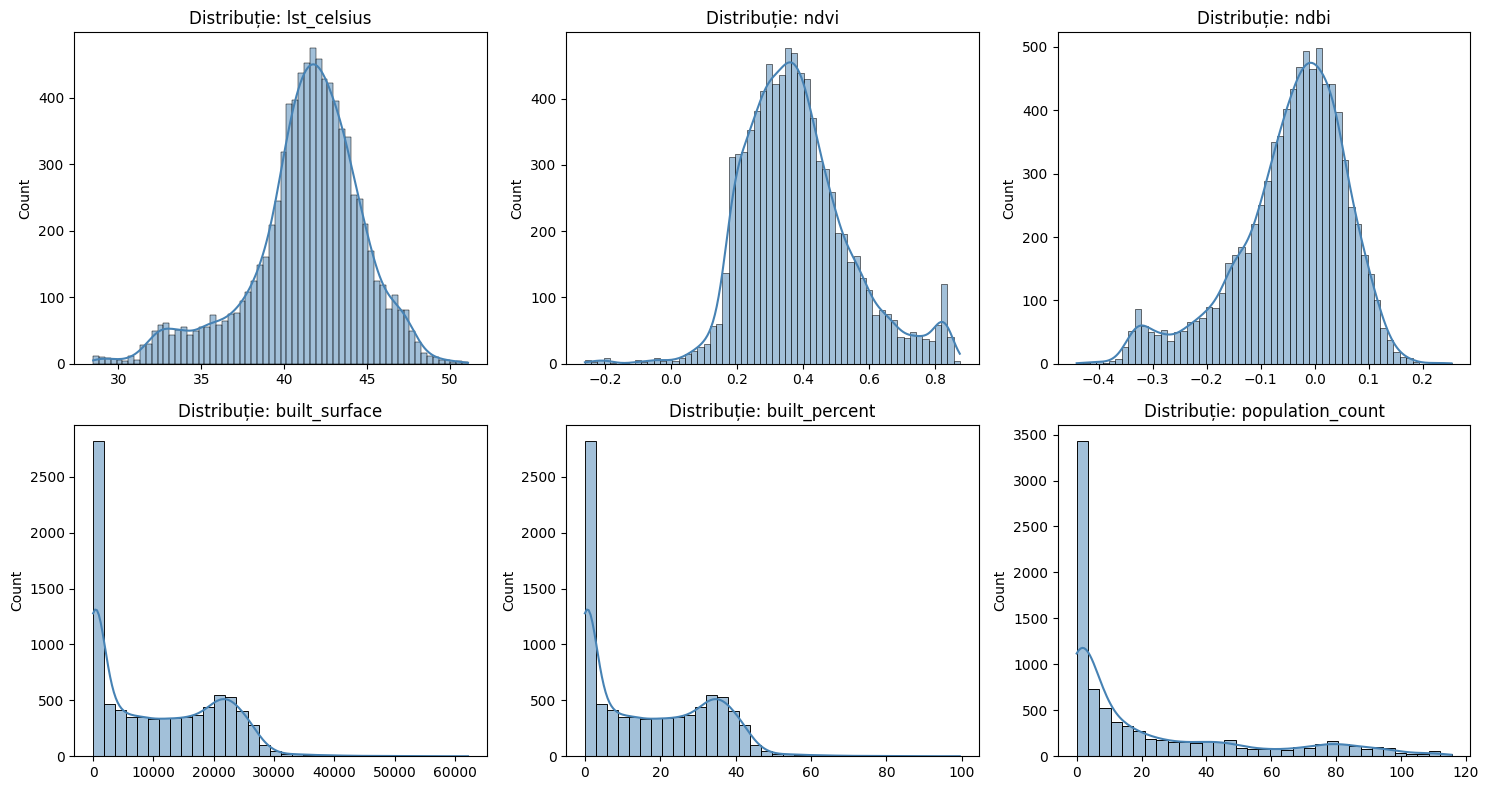

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Statistici descriptive extinse
stats_df = df_clean[feature_cols].describe().T
stats_df['skewness'] = df_clean[feature_cols].skew()
stats_df['kurtosis'] = df_clean[feature_cols].kurt()

print("--- STATISTICI DESCRIPTIVE UNIVARIATE ---")
display(stats_df[['mean', 'std', 'min', '50%', 'max', 'skewness', 'kurtosis']])

# 2. Histograme + KDE pentru identificarea asimetriilor
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(feature_cols):
    sns.histplot(df_clean[col], kde=True, ax=axes[i], color='steelblue')
    axes[i].set_title(f"Distribuție: {col}")
    axes[i].set_xlabel("")

plt.tight_layout()
plt.show()

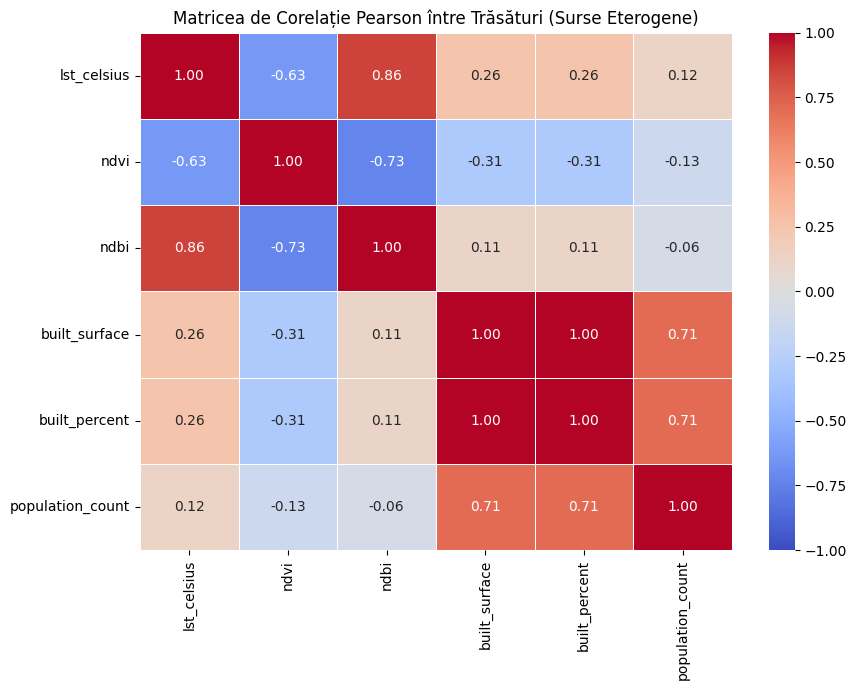

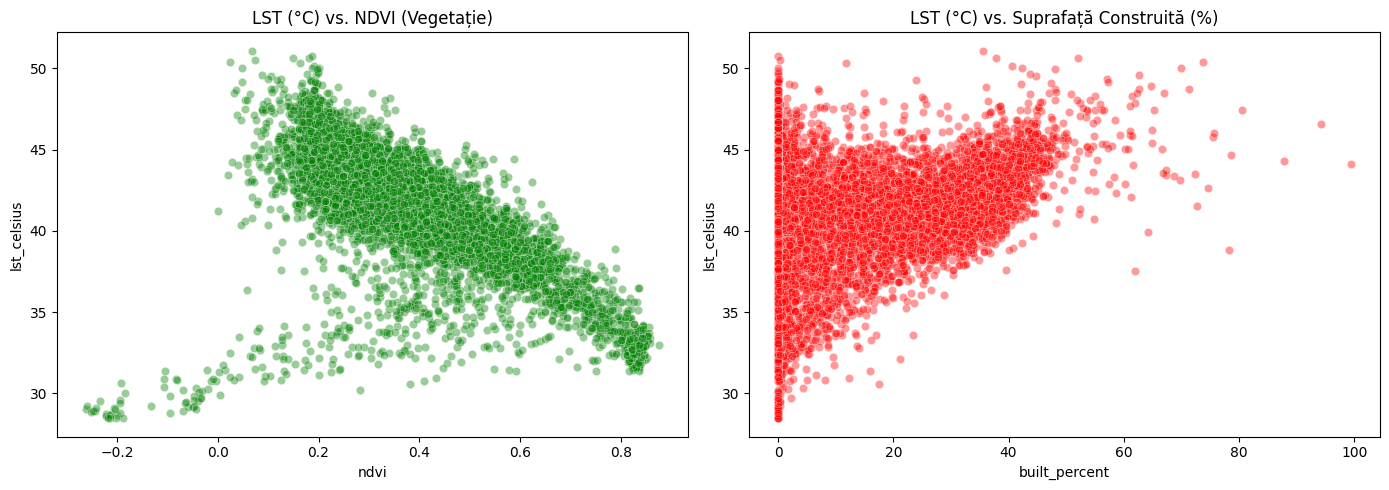

In [24]:
# 1. Calculul matricei de corelație Pearson
corr_matrix = df_clean[feature_cols].corr()

# 2. Plotting Heatmap
plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title("Matricea de Corelație Pearson între Trăsături (Surse Eterogene)")
plt.tight_layout()
plt.show()

# 3. Scatter plot cheie: LST vs. NDVI și LST vs. Built Percent
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=df_clean, x='ndvi', y='lst_celsius', alpha=0.4, color='green', ax=ax1)
ax1.set_title("LST (°C) vs. NDVI (Vegetație)")

sns.scatterplot(data=df_clean, x='built_percent', y='lst_celsius', alpha=0.4, color='red', ax=ax2)
ax2.set_title("LST (°C) vs. Suprafață Construită (%)")

plt.tight_layout()
plt.show()